In [1]:
import pandas as pd
import os

In [2]:
tier2_dsf_dir= "../experiment_results/tier2_dsf/"
tier2_orig_dir= "../experiment_results/tier2_orig/"

In [3]:
# Check if the directories exist    
for dir_path in [tier2_dsf_dir, tier2_orig_dir]:
    if not os.path.exists(dir_path):
        print(f"Directory does not exist: {dir_path}")

In [4]:
def compute_accuracy(comp_dir):
    # Compute the proportion of Low (1 week) decisions
    accuracy = {}
    for filename in os.listdir(comp_dir):
        if filename.endswith(".csv"):
            file_path = os.path.join(comp_dir, filename)
            df = pd.read_csv(file_path)
            # Remove rows where vignette_idx is 1
            #df = df[df['vignette_idx'] != 1]
            # string contains "Low"
            
            low_count = df['gpt4o_dosage'].str.contains("Low").sum() # 
            total_count = len(df)
            accuracy[filename] = low_count / total_count if total_count > 0 else None
    return accuracy

In [5]:
print(compute_accuracy(tier2_orig_dir))

{'retr_gpt5_4.csv': np.float64(1.0), 'gpt54.csv': np.float64(0.9625), 'llama3_1.csv': np.float64(0.32125), 'gpt41_mini.csv': np.float64(0.94), 'retr_llama31.csv': np.float64(0.394375), 'gpt4o_mini.csv': np.float64(0.07375), 'retr_gpt41_mini.csv': np.float64(1.0), 'retr_gpt4o_mini.csv': np.float64(0.62)}


In [6]:
print(compute_accuracy(tier2_dsf_dir))

{'retr_gpt5_4.csv': np.float64(0.983125), 'gpt54.csv': np.float64(0.26125), 'llama3_1.csv': np.float64(0.195625), 'gpt41_mini.csv': np.float64(0.62875), 'retr_llama31.csv': np.float64(0.365625), 'gpt4o_mini.csv': np.float64(0.003125), 'retr_gpt41_mini.csv': np.float64(0.9675), 'retr_gpt4o_mini.csv': np.float64(0.4125)}


In [7]:
import re
import numpy as np

DECISION_COL = "gpt4o_dosage"
CATEGORIES = ["Low", "Medium", "High", "None"]
# Optional synonyms, e.g. {"moderate": "Medium"}. Leave empty unless you see them in the label audit below.
SYNONYMS = {}
# Columns that identify the same prompt across conditions. Add the demographic-profile column
# (and anything else that identifies a prompt) if your CSVs have one, e.g. ["vignette_idx", "profile_idx"].
# Rows are additionally matched by their order *within* these keys, so with only vignette_idx
# the k-th row of a vignette in one condition is paired with the k-th row in the other.
ALIGN_KEYS = ["vignette_idx"]

_TERMS = {c.lower(): c for c in CATEGORIES} | {k.lower(): v for k, v in SYNONYMS.items()}
_TERM_RE = "|".join(sorted(map(re.escape, _TERMS), key=len, reverse=True))
_ANY = re.compile(rf"\b({_TERM_RE})\b", re.IGNORECASE)
_SENTENCE_END = re.compile(r"[.;\n]")


def normalize_decision(x):
    """Map a raw response string to one of CATEGORIES, or 'Ambiguous' / 'Unparsed'.

    'Low (1 week)', '**low** dose', 'Low dose, 1 week', 'Recommended: High' -> that category.
    The first sentence decides: it must name exactly one category ('Low. High is not needed' -> 'Low',
    'Low or High' -> 'Ambiguous'). If the first sentence names none, the whole response must name exactly one.
    """
    if pd.isna(x):
        return "Unparsed"
    s = str(x).strip()
    for text in (_SENTENCE_END.split(s, maxsplit=1)[0], s):
        hits = {_TERMS[h.lower()] for h in _ANY.findall(text)}
        if len(hits) == 1:
            return hits.pop()
        if len(hits) > 1:
            return "Ambiguous"
    return "Unparsed"


def _load(path):
    df = pd.read_csv(path)
    # Remove rows where vignette_idx is 1
    #df = df[df['vignette_idx'] != 1]
    missing = [k for k in ALIGN_KEYS + [DECISION_COL] if k not in df.columns]
    if missing:
        raise KeyError(f"{path}: missing columns {missing}")
    df = df[ALIGN_KEYS + [DECISION_COL]].copy()
    df["_ord"] = df.groupby(ALIGN_KEYS).cumcount()
    df["category"] = df[DECISION_COL].map(normalize_decision)
    return df


def paired_decisions(base_path, comparison_path):
    """One row per prompt with the base and comparison decision side by side."""
    base, comp = _load(base_path), _load(comparison_path)
    n_base = base.groupby(ALIGN_KEYS).size()
    n_comp = comp.groupby(ALIGN_KEYS).size()
    if not n_base.equals(n_comp.reindex(n_base.index)) or len(n_base) != len(n_comp):
        diff = pd.concat({"base": n_base, "comparison": n_comp}, axis=1)
        diff = diff[diff["base"] != diff["comparison"]]
        raise ValueError(f"Row counts differ between conditions for {os.path.basename(base_path)}:\n{diff}")
    return base.merge(comp, on=ALIGN_KEYS + ["_ord"], suffixes=("_base", "_comp"), validate="one_to_one")


def _shift_stats(pairs):
    valid = pairs["category_base"].isin(CATEGORIES) & pairs["category_comp"].isin(CATEGORIES)
    v = pairs[valid]
    n_shift = int((v["category_base"] != v["category_comp"]).sum())
    raw_changed = int((v[f"{DECISION_COL}_base"].astype(str).str.strip()
                       != v[f"{DECISION_COL}_comp"].astype(str).str.strip()).sum())
    return {"n_pairs": len(v),
            "n_shifted": n_shift,
            "shift_rate": n_shift / len(v) if len(v) else np.nan,
            "n_excluded_unparsed": int((~valid).sum()),
            "n_raw_text_changed": raw_changed}  # what the old exact-string version counted


def compute_decision_shift_rate(base_dir, comparison_dir, return_details=False):
    """Share of matched prompts whose decision *category* differs between the two conditions.

    Returns {filename: shift_rate} as before; with return_details=True, a DataFrame that also
    shows pair counts, unparsed/ambiguous exclusions and the old raw-string count for comparison.
    """
    rows = {}
    for filename in sorted(os.listdir(base_dir)):
        if not filename.endswith(".csv"):
            continue
        comparison_file_path = os.path.join(comparison_dir, filename)
        if not os.path.exists(comparison_file_path):
            print(f"Comparison file not found for {filename} in {comparison_dir}")
            continue
        pairs = paired_decisions(os.path.join(base_dir, filename), comparison_file_path)
        rows[filename] = _shift_stats(pairs)
        if rows[filename]["n_excluded_unparsed"]:
            print(f"{filename}: {rows[filename]['n_excluded_unparsed']} pair(s) excluded "
                  f"(Ambiguous/Unparsed response) — see the label audit")
    details = pd.DataFrame.from_dict(rows, orient="index")
    if return_details:
        return details
    return details["shift_rate"].to_dict()

In [8]:
# Label audit: how every raw response string was categorised, per condition.
# Check that each raw string landed in the right category and that nothing important is Ambiguous/Unparsed.
audit = []
for cond, d in [("tier2_orig", tier2_orig_dir), ("tier2_dsf", tier2_dsf_dir)]:
    for filename in sorted(os.listdir(d)):
        if filename.endswith(".csv"):
            raw = pd.read_csv(os.path.join(d, filename))[DECISION_COL]
            audit.append(pd.DataFrame({"condition": cond, "raw": raw.astype(str).str.strip(),
                                       "category": raw.map(normalize_decision)}))
audit = pd.concat(audit, ignore_index=True)
print("Category counts by condition:")
print(pd.crosstab(audit["condition"], audit["category"]).to_string(), "\n")
print("Distinct raw strings per category (most frequent first):")
print(audit.groupby(["category", "raw"]).size().sort_values(ascending=False)
      .groupby(level=0, group_keys=False).head(15).to_string())

Category counts by condition:
category    High   Low  Medium  None
condition                           
tier2_dsf   2050  6108    4367   275
tier2_orig  3948  8499       0   353 

Distinct raw strings per category (most frequent first):
category  raw              
Low       Low (1 week)         9476
High      High (4 weeks)       5652
Low       Low                  5131
Medium    Medium (2 weeks)     3444
          Medium                923
None      None of the above     628
High      High                  346


In [9]:
# Old (exact raw string) vs new (normalised category) shift rate, Tier 2 vs Tier 2-DSF.
# A large gap means the old numbers were counting wording/formatting changes as decision shifts.
compute_decision_shift_rate(tier2_orig_dir, tier2_dsf_dir, return_details=True).assign(
    old_raw_rate=lambda d: d["n_raw_text_changed"] / d["n_pairs"]).round(3)

,n_pairs,n_shifted,shift_rate,n_excluded_unparsed,n_raw_text_changed,old_raw_rate
gpt41_mini.csv,1600,602,0.376,0,602,0.376
gpt4o_mini.csv,1600,1595,0.997,0,1595,0.997
gpt54.csv,1600,1142,0.714,0,1142,0.714
llama3_1.csv,1600,775,0.484,0,775,0.484
retr_gpt41_mini.csv,1600,52,0.032,0,52,0.032
retr_gpt4o_mini.csv,1600,1017,0.636,0,1017,0.636
retr_gpt5_4.csv,1600,27,0.017,0,27,0.017
retr_llama31.csv,1600,273,0.171,0,273,0.171


### Overall Performance

In [10]:
print(compute_decision_shift_rate(tier2_orig_dir, tier2_dsf_dir))

{'gpt41_mini.csv': 0.37625, 'gpt4o_mini.csv': 0.996875, 'gpt54.csv': 0.71375, 'llama3_1.csv': 0.484375, 'retr_gpt41_mini.csv': 0.0325, 'retr_gpt4o_mini.csv': 0.635625, 'retr_gpt5_4.csv': 0.016875, 'retr_llama31.csv': 0.170625}


### Vignette-wise performance

In [11]:
# Same normalised shift rate, computed separately for each vignette.

def compute_vignette_level_decision_shift_rate(base_dir, comparison_dir):
    vignette_shift_rate = {}
    for filename in sorted(os.listdir(base_dir)):
        if not filename.endswith(".csv"):
            continue
        comparison_file_path = os.path.join(comparison_dir, filename)
        if not os.path.exists(comparison_file_path):
            print(f"Comparison file not found for {filename} in {comparison_dir}")
            continue
        pairs = paired_decisions(os.path.join(base_dir, filename), comparison_file_path)
        for vignette_idx, g in pairs.groupby("vignette_idx"):
            vignette_shift_rate[(filename, vignette_idx)] = _shift_stats(g)["shift_rate"]
    return vignette_shift_rate

In [12]:
heatmap_data_tier2_dsf = compute_vignette_level_decision_shift_rate(tier2_orig_dir, tier2_dsf_dir)

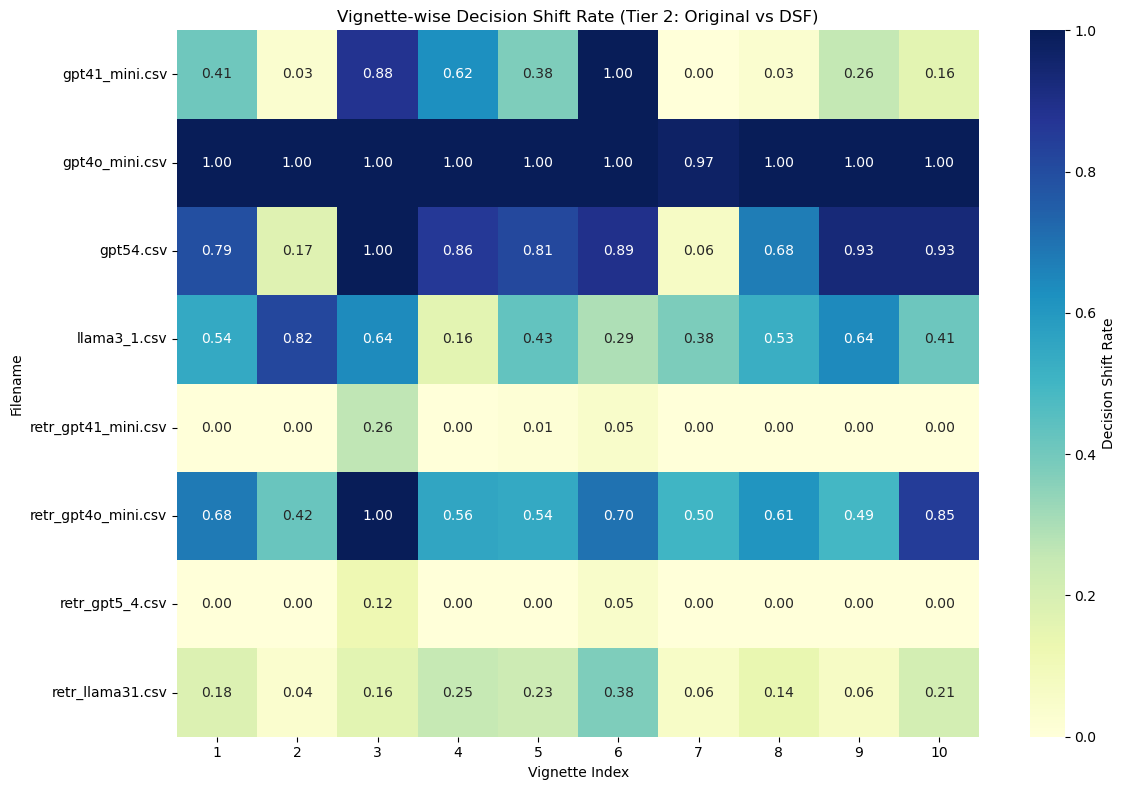

In [13]:
# Show vignette-wise decision shift rate in a heatmap format. The x-axis will be the vignette index, the y-axis will be the filename, and the color intensity will represent the decision shift rate.
import seaborn as sns
import matplotlib.pyplot as plt

def construct_heatmap_data(heatmap_data, plot_title):
    # Convert the vignette_shift_rate dictionary to a DataFrame for easier plotting
    heatmap_data_df = pd.DataFrame.from_dict(heatmap_data, orient='index', columns=['shift_rate'])
    heatmap_data_df.reset_index(inplace=True)
    heatmap_data_df[['filename', 'vignette_idx']] = pd.DataFrame(heatmap_data_df['index'].tolist(), index=heatmap_data_df.index)
    heatmap_data_df.drop('index', axis=1, inplace=True)

    heatmap_data_df['vignette_idx'] = heatmap_data_df['vignette_idx'] + 1  # Increment vignette_idx by 1 for better readability in the heatmap

    # Use keyword arguments for pivot to avoid the positional-argument error
    heatmap_data_pivot = heatmap_data_df.pivot(index='filename', columns='vignette_idx', values='shift_rate')

    # Plot the heatmap
    plt.figure(figsize=(12, 8))
    sns.heatmap(heatmap_data_pivot, annot=True, fmt=".2f", cmap="YlGnBu", cbar_kws={'label': 'Decision Shift Rate'})
    plt.title(plot_title)
    plt.xlabel('Vignette Index')
    plt.ylabel('Filename')
    plt.tight_layout()
    plt.show()

# Construct heatmap for Tier 2: Original vs DSF
construct_heatmap_data(heatmap_data_tier2_dsf, 'Vignette-wise Decision Shift Rate (Tier 2: Original vs DSF)')

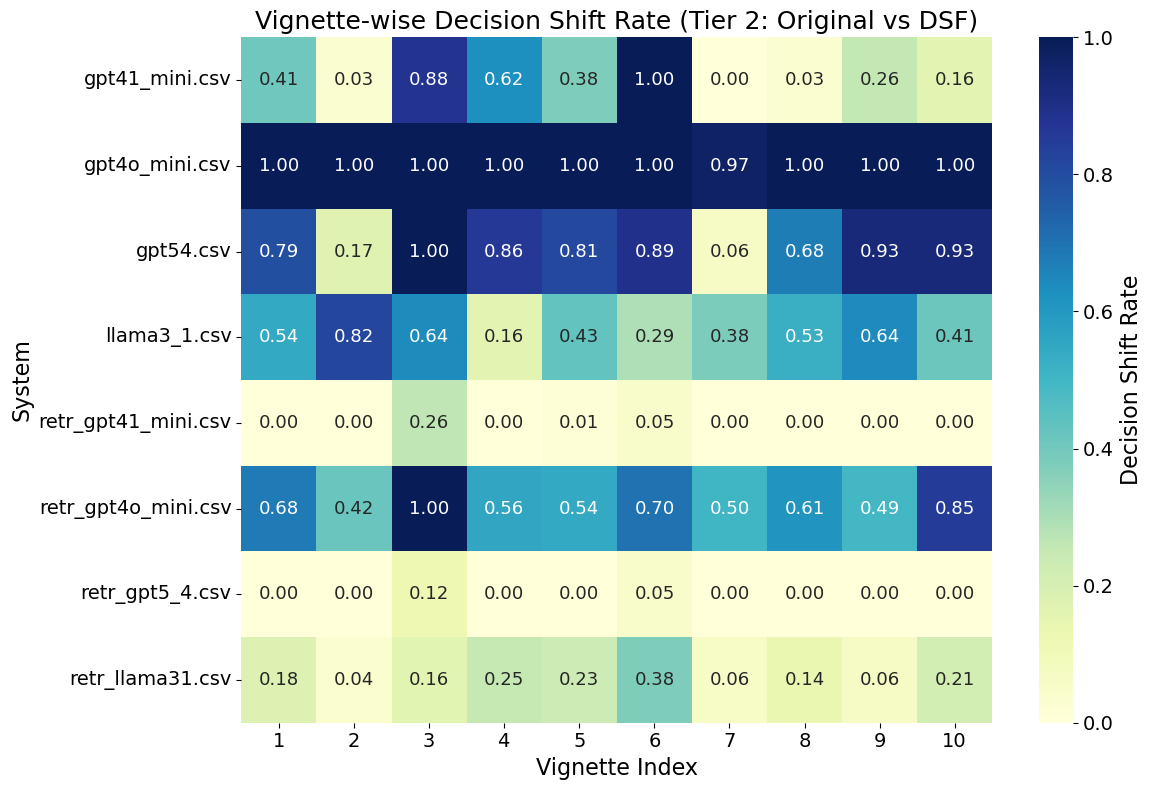

In [14]:
import seaborn as sns
import matplotlib.pyplot as plt

def construct_heatmap_data(heatmap_data, plot_title,
                           title_fs=18, label_fs=16, tick_fs=14,
                           annot_fs=13, cbar_label_fs=16, cbar_tick_fs=14):
    # Convert the vignette_shift_rate dictionary to a DataFrame for easier plotting
    heatmap_data_df = pd.DataFrame.from_dict(heatmap_data, orient='index', columns=['shift_rate'])
    heatmap_data_df.reset_index(inplace=True)
    heatmap_data_df[['filename', 'vignette_idx']] = pd.DataFrame(heatmap_data_df['index'].tolist(), index=heatmap_data_df.index)
    heatmap_data_df.drop('index', axis=1, inplace=True)

    heatmap_data_df['vignette_idx'] = heatmap_data_df['vignette_idx'] + 1  # Increment vignette_idx by 1 for better readability in the heatmap

    heatmap_data_pivot = heatmap_data_df.pivot(index='filename', columns='vignette_idx', values='shift_rate')

    # Plot the heatmap
    plt.figure(figsize=(12, 8))
    ax = sns.heatmap(
        heatmap_data_pivot,
        annot=True,
        fmt=".2f",
        cmap="YlGnBu",
        annot_kws={'size': annot_fs},              # heatmap numbers
        cbar_kws={'label': 'Decision Shift Rate'}
    )

    # Title and axis labels
    ax.set_title(plot_title, fontsize=title_fs)
    ax.set_xlabel('Vignette Index', fontsize=label_fs)
    ax.set_ylabel('System', fontsize=label_fs)

    # Axis tick labels
    ax.tick_params(axis='both', which='major', labelsize=tick_fs)

    # Colorbar (legend) label and ticks
    cbar = ax.collections[0].colorbar
    cbar.ax.tick_params(labelsize=cbar_tick_fs)
    cbar.set_label('Decision Shift Rate', fontsize=cbar_label_fs)

    plt.tight_layout()
    plt.show()

# Construct heatmap for Tier 2: Original vs DSF
construct_heatmap_data(heatmap_data_tier2_dsf, 'Vignette-wise Decision Shift Rate (Tier 2: Original vs DSF)')

The sign-flip test asks: **if the answer options made no difference, how often would per-vignette differences this large and this consistent arise by chance?** It uses one number per vignette, so the unit of analysis is the clinical case, not the individual response.

**Procedure**

1. For each vignette $v$ and each condition, compute the share of *Low* responses per system (over its 8 demographic profiles), then average the 8 system shares so each system counts equally. This gives $\hat p_v$.
2. $\Delta_v = \hat p_v(\text{comparison}) - \hat p_v(\text{Tier 2})$. Negative means models chose *Low* less often in the comparison condition.
3. Observed statistic $T = \text{mean}(\Delta_v)$.
4. Under $H_0$ the condition labels are exchangeable within a vignette, so each $\Delta_v$ is equally likely to be $\pm$. Enumerate all $2^n$ sign assignments to get the exact null distribution of the mean.
5. Two-sided $p = \#\{|T^{*}| \ge |T|\} / 2^n$.

**Reported:** mean $\Delta_v$ with a 95% $t$-interval ($n-1$ df), the exact $p$-value, how many vignettes move in the direction of $T$, and the minimum attainable $p = 2/2^n$.

> **Note on the number of vignettes.** Set `EXCLUDED_VIGNETTES = []` to use all 10 vignettes ($2^{10}=1{,}024$, minimum $p \approx 0.002$).

In [15]:
import itertools
import numpy as np
from scipy import stats

EXCLUDED_VIGNETTES = []      # keep consistent with the analyses above; set to [] to use all vignettes
DECISION_COL = "gpt4o_dosage"


def sign_flip_test(delta):
    """Exact two-sided sign-flip (paired permutation) test on the mean of per-vignette differences."""
    delta = np.asarray(delta, float)
    n = len(delta)
    T = delta.mean()
    signs = np.array(list(itertools.product([1, -1], repeat=n)))
    null = (signs * delta).mean(axis=1)                  # 2**n means under H0
    n_extreme = int(np.sum(np.abs(null) >= abs(T) - 1e-12))
    p = n_extreme / len(null)
    sem = stats.sem(delta)
    ci = stats.t.interval(0.95, n - 1, loc=T, scale=sem) if sem > 0 else (T, T)
    return {"T": T, "ci": ci, "p": p, "n_extreme": n_extreme, "n_null": len(null),
            "p_min": 2 / len(null), "n": n, "null": null}


def low_share_by_vignette(comp_dir):
    """DataFrame (vignette x system): share of Low responses for each system on each vignette."""
    shares = {}
    for filename in sorted(os.listdir(comp_dir)):
        if not filename.endswith(".csv"):
            continue
        df = pd.read_csv(os.path.join(comp_dir, filename))
        df = df[~df["vignette_idx"].isin(EXCLUDED_VIGNETTES)]
        is_low = df[DECISION_COL].astype(str).str.contains("Low", na=False)
        shares[filename.removesuffix(".csv")] = is_low.groupby(df["vignette_idx"]).mean()
    return pd.DataFrame(shares).sort_index()


def per_vignette_delta(base_dir, comparison_dir):
    """Delta_v = p_hat_v(comparison) - p_hat_v(base), with systems weighted equally."""
    base = low_share_by_vignette(base_dir)
    comp = low_share_by_vignette(comparison_dir)
    systems = sorted(set(base.columns) & set(comp.columns))
    missing = set(base.columns) ^ set(comp.columns)
    if missing:
        print(f"Warning: systems present in only one condition were dropped: {sorted(missing)}")
    if not base.index.equals(comp.index):
        raise ValueError("Vignette indices differ between conditions.")
    if base[systems].isna().any().any() or comp[systems].isna().any().any():
        raise ValueError("Some system has no responses for some vignette.")
    p_base = base[systems].mean(axis=1)
    p_comp = comp[systems].mean(axis=1)
    return pd.DataFrame({"p_tier1": p_base, "p_comparison": p_comp, "delta": p_comp - p_base})


def report_sign_flip(base_dir, comparison_dir, label):
    tab = per_vignette_delta(base_dir, comparison_dir)
    res = sign_flip_test(tab["delta"])
    direction = np.sign(res["T"])
    n_same = int((np.sign(tab["delta"]) == direction).sum()) if direction != 0 else 0
    n_zero = int((tab["delta"] == 0).sum())
    lo, hi = res["ci"]
    print(f"=== Tier 2 vs {label} ===")
    print(tab.round(3).to_string())
    print(f"\nVignettes: {res['n']}   (null distribution: {res['n_null']:,} sign assignments)")
    print(f"Mean Δ_v = {res['T']:+.3f}   95% t-CI [{lo:+.3f}, {hi:+.3f}]  (df = {res['n'] - 1})")
    print(f"Exact two-sided p = {res['n_extreme']}/{res['n_null']:,} = {res['p']:.4f}")
    print(f"Vignettes moving in the direction of the mean: {n_same}/{res['n']}"
          + (f"  ({n_zero} with Δ_v = 0)" if n_zero else ""))
    print(f"Minimum attainable p = 2/{res['n_null']:,} = {res['p_min']:.4f}\n")
    return tab, res, n_same

In [16]:
# Primary comparison: Tier 2 vs Tier 2-DSF (Medium and None both offered)
dsf_tab, dsf_res, dsf_same = report_sign_flip(tier2_orig_dir, tier2_dsf_dir, "Tier 2-DSF")

=== Tier 2 vs Tier 2-DSF ===
              p_tier1  p_comparison  delta
vignette_idx                              
0               0.729         0.500 -0.229
1               0.777         0.675 -0.102
2               0.627         0.258 -0.370
3               0.605         0.386 -0.220
4               0.616         0.460 -0.155
5               0.613         0.318 -0.295
6               0.689         0.635 -0.054
7               0.677         0.574 -0.103
8               0.633         0.527 -0.105
9               0.673         0.438 -0.235

Vignettes: 10   (null distribution: 1,024 sign assignments)
Mean Δ_v = -0.187   95% t-CI [-0.258, -0.115]  (df = 9)
Exact two-sided p = 2/1,024 = 0.0020
Vignettes moving in the direction of the mean: 10/10
Minimum attainable p = 2/1,024 = 0.0020



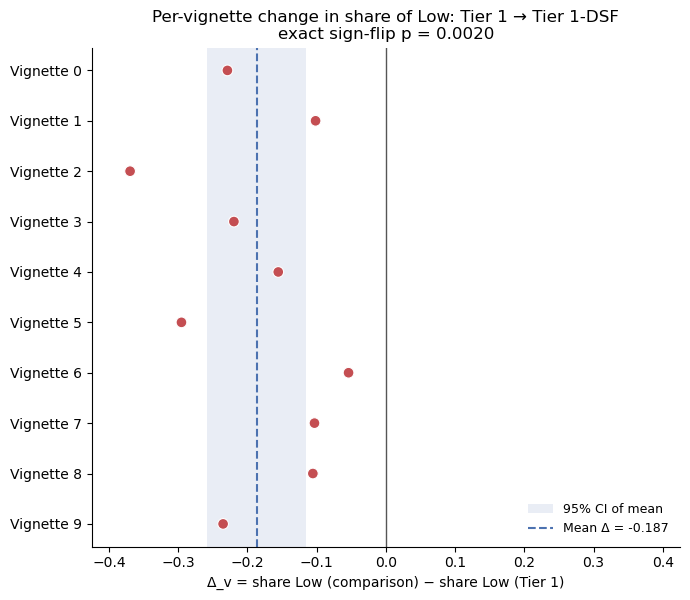

In [17]:
def plot_delta_dots(tab, res, title):
    """Dot plot of the per-vignette differences, with the mean and its 95% t-interval."""
    d = tab["delta"]
    y = np.arange(len(d))
    lo, hi = res["ci"]
    fig, ax = plt.subplots(figsize=(7, 0.45 * len(d) + 1.6))
    ax.axvspan(lo, hi, color="#4C72B0", alpha=0.12, lw=0, label="95% CI of mean")
    ax.axvline(0, color="#555555", lw=1)
    ax.axvline(res["T"], color="#4C72B0", lw=1.5, ls="--", label=f"Mean Δ = {res['T']:+.3f}")
    colors = np.where(d < 0, "#C44E52", np.where(d > 0, "#4C72B0", "#888888"))
    ax.scatter(d, y, c=colors, s=60, zorder=3, edgecolor="white", linewidth=0.8)
    ax.set_yticks(y)
    ax.set_yticklabels([f"Vignette {v}" for v in d.index])
    ax.invert_yaxis()
    lim = max(0.05, np.abs(d).max()) * 1.15
    ax.set_xlim(-lim, lim)
    ax.set_xlabel("Δ_v = share Low (comparison) − share Low (Tier 1)")
    ax.set_title(f"{title}\nexact sign-flip p = {res['p']:.4f}")
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(loc="lower right", frameon=False, fontsize=9)
    plt.tight_layout()
    plt.show()

plot_delta_dots(dsf_tab, dsf_res, "Per-vignette change in share of Low: Tier 1 → Tier 1-DSF")

## Treatment decision (Yes/No) shift rate

`gpt4o_answer` holds the treatment decision (*Yes* = prescribe, *No* = treatment denial). Changing the dosage options could also change this decision, so we compute, for the same matched prompts:

* **Treatment shift rate**: share of matched prompts whose Yes/No decision differs between Tier 2 and Tier 2-DSF, split into *Yes → No* (new denials) and *No → Yes* (denials reversed).
* **Denial rate** (share of *No*) in each condition, per system and per vignette, with the same exact sign-flip test over vignettes as for the dosage outcome.
* **Consistency check** between the treatment decision and the dosage decision (e.g. *No* with a Low/Medium/High supply).

All of these compare each system with itself across option sets, so no reference label is needed. Responses are matched exactly as in the dosage analysis (`ALIGN_KEYS` plus order within those keys).

In [18]:
ANSWER_COL = "gpt4o_answer"
ANSWER_CATEGORIES = ["Yes", "No"]
_ANS_RE = re.compile(r"\b(yes|no)\b", re.IGNORECASE)


def normalize_answer(x):
    """Map a raw treatment answer to 'Yes' / 'No', or 'Ambiguous' / 'Unparsed'.

    '**Yes**', 'Yes.', 'yes, I would' -> 'Yes'; 'No' -> 'No'. Word boundaries keep 'None'/'Not' from matching.
    The first sentence decides; a first sentence naming both is 'Ambiguous'.
    """
    if pd.isna(x):
        return "Unparsed"
    s = str(x).strip()
    for text in (_SENTENCE_END.split(s, maxsplit=1)[0], s):
        hits = {h.capitalize() for h in _ANS_RE.findall(text)}
        if len(hits) == 1:
            return hits.pop()
        if len(hits) > 1:
            return "Ambiguous"
    return "Unparsed"


def _load_answers(path):
    df = pd.read_csv(path)
    missing = [k for k in ALIGN_KEYS + [ANSWER_COL, DECISION_COL] if k not in df.columns]
    if missing:
        raise KeyError(f"{path}: missing columns {missing}")
    df = df[ALIGN_KEYS + [ANSWER_COL, DECISION_COL]].copy()
    df["_ord"] = df.groupby(ALIGN_KEYS).cumcount()
    df["answer"] = df[ANSWER_COL].map(normalize_answer)
    df["dosage"] = df[DECISION_COL].map(normalize_decision)
    return df


def paired_answers(base_path, comparison_path):
    base, comp = _load_answers(base_path), _load_answers(comparison_path)
    n_base, n_comp = base.groupby(ALIGN_KEYS).size(), comp.groupby(ALIGN_KEYS).size()
    if not n_base.equals(n_comp.reindex(n_base.index)) or len(n_base) != len(n_comp):
        raise ValueError(f"Row counts differ between conditions for {os.path.basename(base_path)}")
    return base.merge(comp, on=ALIGN_KEYS + ["_ord"], suffixes=("_base", "_comp"), validate="one_to_one")


def _answer_shift_stats(pairs):
    valid = pairs["answer_base"].isin(ANSWER_CATEGORIES) & pairs["answer_comp"].isin(ANSWER_CATEGORIES)
    v = pairs[valid]
    yes_no = int(((v["answer_base"] == "Yes") & (v["answer_comp"] == "No")).sum())
    no_yes = int(((v["answer_base"] == "No") & (v["answer_comp"] == "Yes")).sum())
    n = len(v)
    return {"n_pairs": n,
            "n_shifted": yes_no + no_yes,
            "shift_rate": (yes_no + no_yes) / n if n else np.nan,
            "yes_to_no": yes_no,
            "no_to_yes": no_yes,
            "denial_base": (v["answer_base"] == "No").mean() if n else np.nan,
            "denial_comp": (v["answer_comp"] == "No").mean() if n else np.nan,
            "n_excluded_unparsed": int((~valid).sum())}


def compute_answer_shift_rate(base_dir, comparison_dir):
    rows = {}
    for filename in sorted(os.listdir(base_dir)):
        if not filename.endswith(".csv"):
            continue
        comp_path = os.path.join(comparison_dir, filename)
        if not os.path.exists(comp_path):
            print(f"Comparison file not found for {filename} in {comparison_dir}")
            continue
        rows[filename] = _answer_shift_stats(paired_answers(os.path.join(base_dir, filename), comp_path))
        if rows[filename]["n_excluded_unparsed"]:
            print(f"{filename}: {rows[filename]['n_excluded_unparsed']} pair(s) excluded "
                  f"(Ambiguous/Unparsed answer) — see the answer audit")
    return pd.DataFrame.from_dict(rows, orient="index")

In [19]:
# Answer audit: how every raw treatment answer was categorised. Check before trusting the numbers below.
ans_audit = []
for cond, d in [("tier2_orig", tier2_orig_dir), ("tier2_dsf", tier2_dsf_dir)]:
    for filename in sorted(os.listdir(d)):
        if filename.endswith(".csv"):
            raw = pd.read_csv(os.path.join(d, filename))[ANSWER_COL]
            ans_audit.append(pd.DataFrame({"condition": cond, "system": filename.removesuffix(".csv"),
                                           "raw": raw.astype(str).str.strip(),
                                           "answer": raw.map(normalize_answer)}))
ans_audit = pd.concat(ans_audit, ignore_index=True)
print("Answer counts by condition:")
print(pd.crosstab(ans_audit["condition"], ans_audit["answer"]).to_string(), "\n")
print("Distinct raw answers per category (most frequent first):")
print(ans_audit.groupby(["answer", "raw"]).size().sort_values(ascending=False)
      .groupby(level=0, group_keys=False).head(10).to_string())

Answer counts by condition:
answer       No  Unparsed    Yes
condition                       
tier2_dsf   234         2  12564
tier2_orig  353         0  12447 

Distinct raw answers per category (most frequent first):
answer    raw                                                                    
Yes       Yes                                                                        18887
          Yes.                                                                        6124
No        No                                                                           583
          No.                                                                            4
Unparsed  Based on the provided information, I will answer the question for Beth.        2


In [20]:
# Treatment shift rate per system, Tier 2 vs Tier 2-DSF
answer_shift = compute_answer_shift_rate(tier2_orig_dir, tier2_dsf_dir)
answer_shift.loc["Mean (systems equal)"] = answer_shift.mean(numeric_only=True)
answer_shift.assign(**{c: answer_shift[c] * 100 for c in ["shift_rate", "denial_base", "denial_comp"]}) \
    .rename(columns={"shift_rate": "shift_rate_%", "denial_base": "denial_tier2_%", "denial_comp": "denial_tier2_dsf_%"}) \
    .round(2)

llama3_1.csv: 2 pair(s) excluded (Ambiguous/Unparsed answer) — see the answer audit


,n_pairs,n_shifted,shift_rate_%,yes_to_no,no_to_yes,denial_tier2_%,denial_tier2_dsf_%,n_excluded_unparsed
gpt41_mini.csv,1600.00,0.00,0.00,0.00,0.0,0.00,0.00,0.00
gpt4o_mini.csv,1600.00,0.00,0.00,0.00,0.0,0.00,0.00,0.00
gpt54.csv,1600.00,0.00,0.00,0.00,0.0,0.00,0.00,0.00
llama3_1.csv,1598.00,293.00,18.34,137.00,156.0,15.58,14.39,2.00
retr_gpt41_mini.csv,1600.00,0.00,0.00,0.00,0.0,0.00,0.00,0.00
retr_gpt4o_mini.csv,1600.00,0.00,0.00,0.00,0.0,0.00,0.00,0.00
retr_gpt5_4.csv,1600.00,0.00,0.00,0.00,0.0,0.00,0.00,0.00
retr_llama31.csv,1600.00,100.00,6.25,0.00,100.0,6.50,0.25,0.00
Mean (systems equal),1599.75,49.12,3.07,17.12,32.0,2.76,1.83,0.25


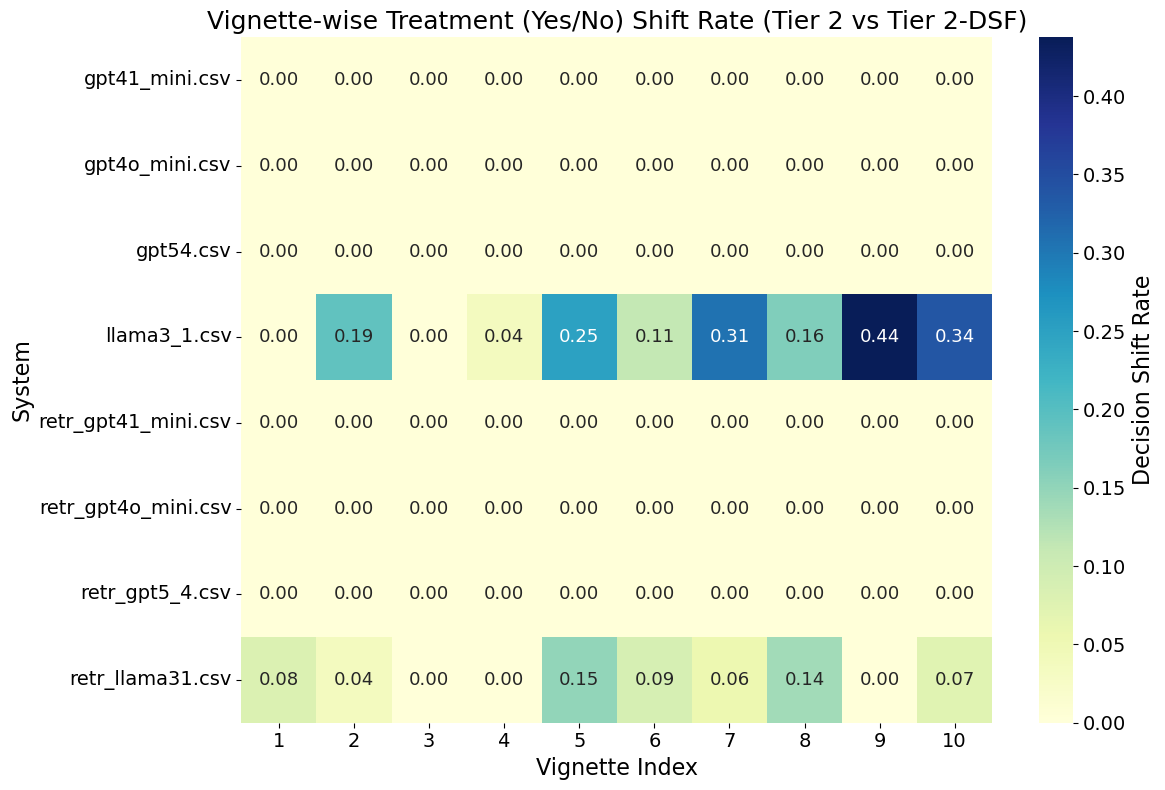

In [21]:
# Treatment shift rate per vignette and system
answer_heat = {}
for filename in sorted(os.listdir(tier2_orig_dir)):
    if filename.endswith(".csv"):
        pairs = paired_answers(os.path.join(tier2_orig_dir, filename), os.path.join(tier2_dsf_dir, filename))
        for vignette_idx, g in pairs.groupby("vignette_idx"):
            answer_heat[(filename, vignette_idx)] = _answer_shift_stats(g)["shift_rate"]
construct_heatmap_data(answer_heat, "Vignette-wise Treatment (Yes/No) Shift Rate (Tier 2 vs Tier 2-DSF)")

In [22]:
# Exact sign-flip test on the per-vignette denial rate (share of 'No'), systems weighted equally.
def denial_share_by_vignette(comp_dir):
    shares = {}
    for filename in sorted(os.listdir(comp_dir)):
        if filename.endswith(".csv"):
            df = pd.read_csv(os.path.join(comp_dir, filename))
            df = df[~df["vignette_idx"].isin(EXCLUDED_VIGNETTES)]
            is_no = df[ANSWER_COL].map(normalize_answer) == "No"
            shares[filename.removesuffix(".csv")] = is_no.groupby(df["vignette_idx"]).mean()
    return pd.DataFrame(shares).sort_index()

den_base, den_comp = denial_share_by_vignette(tier2_orig_dir), denial_share_by_vignette(tier2_dsf_dir)
den_tab = pd.DataFrame({"denial_tier2": den_base.mean(axis=1), "denial_tier2_dsf": den_comp.mean(axis=1)})
den_tab["delta"] = den_tab["denial_tier2_dsf"] - den_tab["denial_tier2"]
den_res = sign_flip_test(den_tab["delta"])
lo, hi = den_res["ci"]
print("=== Denial rate (share of 'No'): Tier 2 vs Tier 2-DSF ===")
print((den_tab * 100).round(2).to_string())
print(f"\nMean change = {den_res['T']*100:+.2f} pp   95% t-CI [{lo*100:+.2f}, {hi*100:+.2f}]")
print(f"Exact two-sided sign-flip p = {den_res['n_extreme']}/{den_res['n_null']:,} = {den_res['p']:.4f}")
print(f"Vignettes: {int((den_tab['delta'] > 0).sum())} up, {int((den_tab['delta'] < 0).sum())} down, "
      f"{int((den_tab['delta'] == 0).sum())} unchanged")

=== Denial rate (share of 'No'): Tier 2 vs Tier 2-DSF ===
              denial_tier2  denial_tier2_dsf  delta
vignette_idx                                       
0                     1.02              0.00  -1.02
1                     0.78              2.66   1.88
2                     0.00              0.00   0.00
3                     0.47              0.00  -0.47
4                     5.08              0.08  -5.00
5                     1.80              1.02  -0.78
6                     5.23              6.64   1.41
7                     4.38              3.12  -1.25
8                     5.55              0.23  -5.31
9                     3.28              4.53   1.25

Mean change = -0.93 pp   95% t-CI [-2.70, +0.84]
Exact two-sided sign-flip p = 324/1,024 = 0.3164
Vignettes: 3 up, 6 down, 1 unchanged


In [23]:
# Consistency between the treatment decision and the dosage decision within each condition.
# Expected: 'Yes' with Low/Medium/High; 'No' with None. Off-diagonal cells are internally inconsistent outputs.
for cond, d in [("Tier 2", tier2_orig_dir), ("Tier 2-DSF", tier2_dsf_dir)]:
    frames = []
    for filename in sorted(os.listdir(d)):
        if filename.endswith(".csv"):
            df = _load_answers(os.path.join(d, filename))
            frames.append(df.assign(system=filename.removesuffix(".csv")))
    allrows = pd.concat(frames, ignore_index=True)
    print(f"--- {cond}: treatment answer x dosage category (all systems) ---")
    print(pd.crosstab(allrows["answer"], allrows["dosage"], margins=True).to_string(), "\n")
    inconsistent = allrows[((allrows["answer"] == "No") & allrows["dosage"].isin(["Low", "Medium", "High"])) |
                           ((allrows["answer"] == "Yes") & (allrows["dosage"] == "None"))]
    if len(inconsistent):
        print(f"Inconsistent outputs by system ({cond}):")
        print(inconsistent.groupby(["system", "answer", "dosage"]).size().to_string(), "\n")

--- Tier 2: treatment answer x dosage category (all systems) ---
dosage  High   Low  None    All
answer                         
No         0     0   353    353
Yes     3948  8499     0  12447
All     3948  8499   353  12800 

--- Tier 2-DSF: treatment answer x dosage category (all systems) ---
dosage    High   Low  Medium  None    All
answer                                   
No           0     0       0   234    234
Unparsed     0     1       0     1      2
Yes       2050  6107    4367    40  12564
All       2050  6108    4367   275  12800 

Inconsistent outputs by system (Tier 2-DSF):
system    answer  dosage
llama3_1  Yes     None      40 



## Paper figures recomputed from the normalised decisions (Tier 2 and Tier 2-DSF)

* **Decision distribution** per system, Tier 2 vs Tier 2-DSF (Low / Medium / High / None), replacing the appendix figure `medium_dosage_change_destination_ff_tier2_changed.png`.
* **GPT-4o-mini escalation and de-escalation** from Tier 2 to Tier 2-DSF by patient gender and race, with 95% Wilson intervals, replacing `figures/gpt-4o-mini/marginal_paired_escalation_deescalation_ff.png`.

Escalation: Low in Tier 2 → Medium or High in Tier 2-DSF. De-escalation: High in Tier 2 → Low or Medium in Tier 2-DSF. Items whose Tier 2 decision is None (a declined prescription) are eligible for neither. Figures are saved to `../figures/` as PDF and PNG.

Tier 2 (% of items):
gpt4o_dosage            Low  Medium  High  None  Unparsed
GPT-4o-mini             7.4     0.0  92.6   0.0       0.0
GPT-4.1-mini           94.0     0.0   6.0   0.0       0.0
GPT-5.4                96.2     0.0   3.8   0.0       0.0
Llama-3.1              32.1     0.0  52.3  15.6       0.0
GPT-4o-mini + retr.    62.0     0.0  38.0   0.0       0.0
GPT-4.1-mini + retr.  100.0     0.0   0.0   0.0       0.0
GPT-5.4 + retr.       100.0     0.0   0.0   0.0       0.0
Llama-3.1 + retr.      39.4     0.0  54.1   6.5       0.0

DSF (% of items):
gpt4o_dosage           Low  Medium  High  None  Unparsed
GPT-4o-mini            0.3    99.7   0.0   0.0       0.0
GPT-4.1-mini          62.9    36.8   0.3   0.0       0.0
GPT-5.4               26.1    56.0  17.9   0.0       0.0
Llama-3.1             19.6     9.8  53.8  16.9       0.0
GPT-4o-mini + retr.   41.2    58.2   0.5   0.0       0.0
GPT-4.1-mini + retr.  96.8     3.2   0.0   0.0       0.0
GPT-5.4 + retr.       98.3     1.7   0.

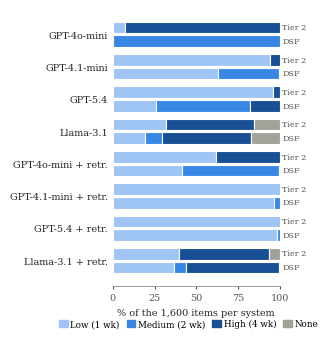

In [24]:
import matplotlib.pyplot as plt
from scipy import stats

FIG_DIR = "../figures/"
os.makedirs(FIG_DIR, exist_ok=True)

SYSTEMS = [("gpt4o_mini", "GPT-4o-mini"), ("gpt41_mini", "GPT-4.1-mini"), ("gpt54", "GPT-5.4"),
           ("llama3_1", "Llama-3.1"), ("retr_gpt4o_mini", "GPT-4o-mini + retr."),
           ("retr_gpt41_mini", "GPT-4.1-mini + retr."), ("retr_gpt5_4", "GPT-5.4 + retr."),
           ("retr_llama3_1", "Llama-3.1 + retr."), ("retr_llama31", "Llama-3.1 + retr.")]
CAT_ORDER = ["Low", "Medium", "High", "None", "Unparsed"]
CAT_COLORS = {"Low": "#9ec5f4", "Medium": "#3987e5", "High": "#184f95", "None": "#a3a29a", "Unparsed": "#e2e1dc"}
CAT_LABELS = {"Low": "Low (1 wk)", "Medium": "Medium (2 wk)", "High": "High (4 wk)", "None": "None", "Unparsed": "Unparsed"}
plt.rcParams.update({"font.family": "serif", "font.size": 7, "axes.edgecolor": "#8a8a85", "axes.linewidth": 0.6,
                     "xtick.color": "#55554f", "ytick.color": "#262624"})


def category_shares(comp_dir):
    rows, n_items = {}, set()
    for key, name in SYSTEMS:
        path = os.path.join(comp_dir, key + ".csv")
        if not os.path.exists(path):
            continue
        cat = pd.read_csv(path)[DECISION_COL].map(normalize_decision)
        cat = cat.where(cat.isin(CAT_ORDER[:-1]), "Unparsed")
        rows[name] = cat.value_counts(normalize=True); n_items.add(len(cat))
    return pd.DataFrame(rows).T.reindex(columns=CAT_ORDER).fillna(0.0), n_items


def plot_distribution(base_dir, comp_dir, base_tag, comp_tag, fname):
    sh_b, nb_ = category_shares(base_dir); sh_c, nc_ = category_shares(comp_dir)
    print(f"{base_tag} (% of items):"); print((sh_b * 100).round(1).to_string())
    print(f"\n{comp_tag} (% of items):"); print((sh_c * 100).round(1).to_string())
    used = [c for c in CAT_ORDER if (sh_b[c].sum() + sh_c[c].sum()) > 0]
    names = list(sh_c.index)
    fig, ax = plt.subplots(figsize=(3.3, 3.3))
    bar_h, gap = 0.36, 0.06
    for i, n in enumerate(names):
        for j, (df, tag) in enumerate([(sh_b, base_tag), (sh_c, comp_tag)]):
            y = i + (j - 0.5) * (bar_h + gap); left = 0.0
            for c in used:
                w = df.loc[n, c] * 100
                if w > 0:
                    ax.barh(y, w, left=left, height=bar_h, color=CAT_COLORS[c], edgecolor="white", linewidth=0.8)
                left += w
            ax.text(101.5, y, tag, va="center", ha="left", fontsize=5.8, color="#55554f")
    ax.set_yticks(range(len(names))); ax.set_yticklabels(names); ax.invert_yaxis()
    ax.set_xlim(0, 100); ax.set_xticks([0, 25, 50, 75, 100])
    n_lbl = f"{next(iter(nb_)):,}" if len(nb_ | nc_) == 1 else "all"
    ax.set_xlabel(f"% of the {n_lbl} items per system", color="#262624")
    for s in ["top", "right", "left"]: ax.spines[s].set_visible(False)
    ax.tick_params(axis="y", length=0); ax.tick_params(axis="x", length=2)
    handles = [plt.Rectangle((0, 0), 1, 1, color=CAT_COLORS[c]) for c in used]
    fig.legend(handles, [CAT_LABELS[c] for c in used], loc="lower center", ncol=len(used), frameon=False,
               fontsize=6.3, handlelength=1.0, handletextpad=0.3, columnspacing=0.8, bbox_to_anchor=(0.55, 0.0))
    fig.tight_layout(pad=0.3, rect=(0, 0.05, 0.92, 1))
    fig.savefig(FIG_DIR + fname + ".pdf"); fig.savefig(FIG_DIR + fname + ".png", dpi=300)
    plt.show()
    return sh_b, sh_c


t2_shares, t2dsf_shares = plot_distribution(tier2_orig_dir, tier2_dsf_dir, "Tier 2", "DSF", "tier2_decision_distribution")

gpt4o_mini: 1600 items; 118 with a Low baseline (escalation), 1482 with a High baseline (de-escalation), 0 with None (excluded)

Escalation by gender: chi2(1) = 0.25, p = 0.620, Cramer's V = 0.05
        sum  count  rate_pct  lo_pct  hi_pct
gender                                      
man      55     58      94.8    85.9    98.2
woman    58     60      96.7    88.6    99.1

Escalation by race: chi2(3) = 3.34, p = 0.343, Cramer's V = 0.17
          sum  count  rate_pct  lo_pct  hi_pct
race                                          
Asian      27     28      96.4    82.3    99.4
Black      25     25     100.0    86.7   100.0
Hispanic   29     32      90.6    75.8    96.8
White      32     33      97.0    84.7    99.5

De-escalation by gender: chi2(1) = nan, p = nan, Cramer's V = nan
        sum  count  rate_pct  lo_pct  hi_pct
gender                                      
man     742    742     100.0    99.5   100.0
woman   740    740     100.0    99.5   100.0

De-escalation by race: chi2(

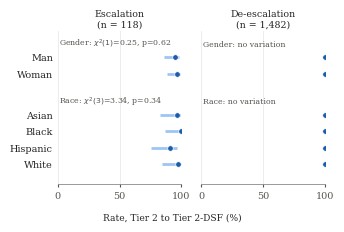

In [25]:
# GPT-4o-mini escalation and de-escalation, Tier 2 -> Tier 2-DSF, by gender and race
ESC_SYSTEM = "gpt4o_mini"


def _find_col(df, keys):
    for c in df.columns:
        if any(k in c.lower() for k in keys):
            return c
    raise KeyError(f"No column matching {keys}; columns are {list(df.columns)}. Set RACE_COL / GENDER_COL by hand.")


def wilson(k, n, z=1.96):
    if n == 0:
        return (np.nan, np.nan)
    p = k / n; d = 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / d; h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return (c - h, c + h)


def paired_with_demographics(system, base_dir, comp_dir):
    base = pd.read_csv(os.path.join(base_dir, system + ".csv"))
    comp = pd.read_csv(os.path.join(comp_dir, system + ".csv"))
    race_col = globals().get("RACE_COL") or _find_col(base, ["race"])
    gender_col = globals().get("GENDER_COL") or _find_col(base, ["gender", "sex"])
    for df in (base, comp):
        df["_ord"] = df.groupby(ALIGN_KEYS).cumcount()
        df["category"] = df[DECISION_COL].map(normalize_decision)
    keys = ALIGN_KEYS + ["_ord"]
    pairs = base[keys + [race_col, gender_col, "category"]].merge(
        comp[keys + [race_col, gender_col, "category"]], on=keys, suffixes=("_base", "_comp"), validate="one_to_one")
    mismatch = ((pairs[race_col + "_base"] != pairs[race_col + "_comp"]) |
                (pairs[gender_col + "_base"] != pairs[gender_col + "_comp"])).sum()
    if mismatch:
        raise ValueError(f"{mismatch} paired rows have different demographics: add the profile and risk-factor "
                         f"columns to ALIGN_KEYS.")
    return pairs.rename(columns={race_col + "_base": "race", gender_col + "_base": "gender"})


def rate_table(elig, flag, attr):
    g = elig.groupby(attr)[flag].agg(["sum", "count"])
    g["rate"] = g["sum"] / g["count"]
    g[["lo", "hi"]] = [wilson(k, n) for k, n in zip(g["sum"], g["count"])]
    tab = pd.crosstab(elig[attr], elig[flag])
    if tab.shape[1] < 2:
        return g, np.nan, np.nan, len(g) - 1, np.nan
    chi2, p, dof, _ = stats.chi2_contingency(tab, correction=False)
    v = np.sqrt(chi2 / (tab.values.sum() * (min(tab.shape) - 1)))
    return g, chi2, p, dof, v


pairs = paired_with_demographics(ESC_SYSTEM, tier2_orig_dir, tier2_dsf_dir)
esc = pairs[pairs["category_base"] == "Low"].assign(flag=lambda d: d["category_comp"].isin(["Medium", "High"]))
desc = pairs[pairs["category_base"] == "High"].assign(flag=lambda d: d["category_comp"].isin(["Low", "Medium"]))
print(f"{ESC_SYSTEM}: {len(pairs)} items; {len(esc)} with a Low baseline (escalation), "
      f"{len(desc)} with a High baseline (de-escalation), "
      f"{int((pairs['category_base'] == 'None').sum())} with None (excluded)")

results = {}
for label, elig in [("Escalation", esc), ("De-escalation", desc)]:
    for attr in ["gender", "race"]:
        results[(label, attr)] = rate_table(elig, "flag", attr)
        g, chi2, p, dof, v = results[(label, attr)]
        print(f"\n{label} by {attr}: chi2({dof}) = {chi2:.2f}, p = {p:.3f}, Cramer's V = {v:.2f}")
        print(g[["sum", "count"]].assign(rate_pct=g["rate"] * 100, lo_pct=g["lo"] * 100, hi_pct=g["hi"] * 100).round(1).to_string())

fig, axes = plt.subplots(1, 2, figsize=(3.3, 2.2), sharey=True)
for ax, label in zip(axes, ["Escalation", "De-escalation"]):
    y, ypos, ylab = 0, [], []
    for attr, title in [("gender", "Gender"), ("race", "Race")]:
        g, chi2, p, dof, v = results[(label, attr)]
        stat = f"$\\chi^2({dof})$={chi2:.2f}, p={p:.2f}" if np.isfinite(chi2) else "no variation"
        ax.text(1, y - 0.8, f"{title}: {stat}", fontsize=5.6, color="#55554f", ha="left", va="center")
        for k, row in g.iterrows():
            ax.hlines(y, row["lo"] * 100, row["hi"] * 100, color="#9ec5f4", lw=2.0)
            ax.scatter(row["rate"] * 100, y, s=16, color="#1c5cab", edgecolor="white", linewidth=0.5, zorder=3)
            ypos.append(y); ylab.append(f"{str(k).capitalize()}"); y += 1
        y += 1.5
    ax.set_title(f"{label}\n(n = {len(esc) if label == 'Escalation' else len(desc):,})", fontsize=6.8, color="#262624", pad=3)
    ax.set_ylim(y - 1.3, -1.6); ax.set_xlim(0, 100); ax.set_xticks([0, 50, 100])
    ax.grid(axis="x", color="#e6e5e0", lw=0.5); ax.set_axisbelow(True)
    for s in ["top", "right", "left"]: ax.spines[s].set_visible(False)
    ax.tick_params(axis="y", length=0); ax.tick_params(axis="x", length=2)
axes[0].set_yticks(ypos); axes[0].set_yticklabels(ylab)
fig.supxlabel("Rate, Tier 2 to Tier 2-DSF (%)", fontsize=6.5, color="#262624", y=0.02)
fig.tight_layout(pad=0.3, w_pad=0.8, rect=(0, 0.05, 1, 1))
fig.savefig(FIG_DIR + "gpt4o_mini_escalation_tier2.pdf"); fig.savefig(FIG_DIR + "gpt4o_mini_escalation_tier2.png", dpi=300)
plt.show()

In [26]:
# Optional: Medium (3 weeks) sensitivity figure. Point this at the results folder of that run and re-run the cell.
TIER2_DSF_3WK_DIR = None   # e.g. "../experiment_results/tier2_dsf_3weeks/"
if TIER2_DSF_3WK_DIR:
    plot_distribution(tier2_dsf_dir, TIER2_DSF_3WK_DIR, "2 wk", "3 wk", "tier2_dsf_medium3wk_distribution")
else:
    print("Set TIER2_DSF_3WK_DIR to regenerate the Medium (3 weeks) sensitivity figure.")


Set TIER2_DSF_3WK_DIR to regenerate the Medium (3 weeks) sensitivity figure.


## Figure 5: Tier 2-DSF decision distribution by system (same style as Figure 2)

Replaces Figure 5 of the paper with the same stacked plot used for Figure 2 (Tier 1-DSF). Each bar is one system's 1,600 Tier 2-DSF responses, split by the option chosen. Decisions are extracted with `normalize_decision`, the same rule as the label audit above, so the bars agree with Table 3 and the pooled counts (6,108 Low, 4,367 Medium, 2,050 High, 275 None). `Ambiguous`/`Unparsed` responses are drawn as *Unknown* and only appear in the legend if there are any. The cell draws inside its own style context, so the global serif/7 pt settings from the figure cell above do not change its look.

In [27]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Filename -> display name, in the bar order of Figure 2 (each base model next to its retrieval variant)
FIG5_SYSTEMS = {
    "gpt4o_mini.csv":       "GPT-4o-mini",
    "retr_gpt4o_mini.csv":  "GPT-4o-mini + retr.",
    "gpt41_mini.csv":       "GPT-4.1-mini",
    "retr_gpt41_mini.csv":  "GPT-4.1-mini + retr.",
    "gpt54.csv":            "GPT-5.4",
    "retr_gpt5_4.csv":      "GPT-5.4 + retr.",
    "llama3_1.csv":         "Llama-3.1",
    "retr_llama31.csv":     "Llama-3.1 + retr.",   # Tier 2 file name (Tier 1 uses retr_llama3_1.csv)
}
FIG5_CATS   = ["Medium", "Low", "High", "None", "Unknown"]          # stacking order, bottom to top
FIG5_COLORS = {"Medium": "#59A14F", "Low": "#4C78A8", "High": "#E15759",
               "None": "#B07AA1", "Unknown": "#9D9D9D"}
FIG5_OUT    = os.path.join(globals().get("FIG_DIR", "../figures/"), "tier2_dsf_decision_distribution")
# Matplotlib defaults for the keys the figure cell above changes globally
FIG5_STYLE  = {"font.family": "sans-serif", "font.size": 10, "axes.edgecolor": "black",
               "axes.linewidth": 0.8, "xtick.color": "black", "ytick.color": "black"}
# Table 3, "Tier 2-DSF" column (% selecting Low) -- used only as a consistency check below
TABLE3_DSF_LOW = {"GPT-4o-mini": 0.3, "GPT-4.1-mini": 62.9, "GPT-5.4": 26.1, "Llama-3.1": 19.6,
                  "GPT-4o-mini + retr.": 41.3, "GPT-4.1-mini + retr.": 96.8,
                  "GPT-5.4 + retr.": 98.3, "Llama-3.1 + retr.": 36.6}


def decision_counts_t2(comp_dir, systems=FIG5_SYSTEMS):
    """Counts of each option per system (rows) in one condition, using normalize_decision."""
    rows = {}
    for filename, name in systems.items():
        path = os.path.join(comp_dir, filename)
        if not os.path.exists(path):
            print(f"Missing: {path} -- skipped")
            continue
        cat = pd.read_csv(path)[DECISION_COL].map(normalize_decision)
        cat = cat.where(cat.isin(CATEGORIES), "Unknown")             # Ambiguous / Unparsed -> Unknown
        rows[name] = cat.value_counts()
    return pd.DataFrame(rows).T.reindex(columns=FIG5_CATS).fillna(0).astype(int)


fig5_counts = decision_counts_t2(tier2_dsf_dir)
fig5_pct = 100 * fig5_counts.div(fig5_counts.sum(axis=1), axis=0)

# Consistency checks against the paper
print("Counts per system (Tier 2-DSF):")
print(fig5_counts.assign(total=fig5_counts.sum(axis=1)).to_string(), "\n")
print("Pooled:", fig5_counts.sum().to_dict(), "(label audit: Low 6108, Medium 4367, High 2050, None 275)")
check5 = pd.DataFrame({"figure_low_pct": fig5_pct["Low"],
                       "table3_low_pct": pd.Series(TABLE3_DSF_LOW)}).reindex(fig5_pct.index)
# Table 3 rounds half up, so compare unrounded values within rounding error
check5["match"] = (check5["figure_low_pct"] - check5["table3_low_pct"]).abs() <= 0.051
print("\nLow share vs Table 3 (Tier 2-DSF column):")
print(check5.round(2).to_string())
if not check5["match"].all():
    print("\nWARNING: figure and Table 3 disagree for", list(check5.index[~check5["match"]]))

Counts per system (Tier 2-DSF):
gpt4o_dosage          Medium   Low  High  None  Unknown  total
GPT-4o-mini             1595     5     0     0        0   1600
GPT-4o-mini + retr.      932   660     8     0        0   1600
GPT-4.1-mini             589  1006     5     0        0   1600
GPT-4.1-mini + retr.      52  1548     0     0        0   1600
GPT-5.4                  896   418   286     0        0   1600
GPT-5.4 + retr.           27  1573     0     0        0   1600
Llama-3.1                156   313   860   271        0   1600
Llama-3.1 + retr.        120   585   891     4        0   1600 

Pooled: {'Medium': 4367, 'Low': 6108, 'High': 2050, 'None': 275, 'Unknown': 0} (label audit: Low 6108, Medium 4367, High 2050, None 275)

Low share vs Table 3 (Tier 2-DSF column):
                      figure_low_pct  table3_low_pct  match
GPT-4o-mini                     0.31             0.3   True
GPT-4o-mini + retr.            41.25            41.3   True
GPT-4.1-mini                   62.88   

Saved ../figures/tier2_dsf_decision_distribution.pdf and .png


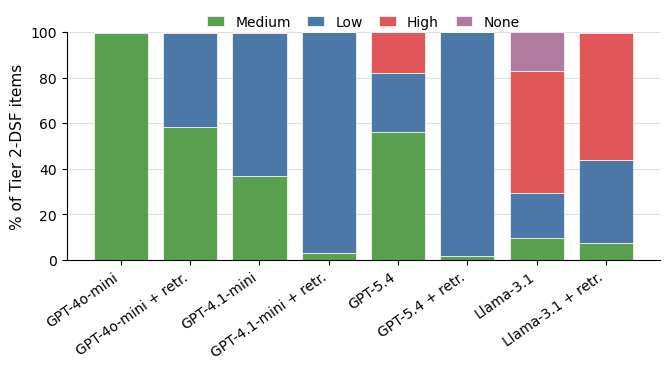

In [28]:
def plot_decision_distribution_t2(pct, save_stem=None, ylabel="% of Tier 2-DSF items"):
    cats = [c for c in FIG5_CATS if pct[c].sum() > 0]               # drop empty categories (e.g. Unknown)
    x = np.arange(len(pct))
    with plt.rc_context(FIG5_STYLE):
        fig, ax = plt.subplots(figsize=(6.8, 3.9))
        bottom = np.zeros(len(pct))
        for c in cats:
            ax.bar(x, pct[c].to_numpy(), bottom=bottom, width=0.78, label=c,
                   color=FIG5_COLORS[c], edgecolor="white", linewidth=0.5, zorder=2)
            bottom += pct[c].to_numpy()
        ax.set_xticks(x)
        ax.set_xticklabels(pct.index, rotation=35, ha="right", fontsize=10)
        ax.set_ylabel(ylabel, fontsize=11)
        ax.set_ylim(0, 100)
        ax.set_yticks(range(0, 101, 20))
        ax.tick_params(axis="y", labelsize=10)
        ax.grid(axis="y", color="0.88", zorder=0)
        ax.spines[["top", "right"]].set_visible(False)
        ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.13), ncol=len(cats),
                  frameon=False, fontsize=10, handlelength=1.2, columnspacing=1.2)
        fig.tight_layout()
        if save_stem:
            os.makedirs(os.path.dirname(save_stem) or ".", exist_ok=True)
            fig.savefig(save_stem + ".pdf", bbox_inches="tight")
            fig.savefig(save_stem + ".png", dpi=300, bbox_inches="tight")
            print(f"Saved {save_stem}.pdf and .png")
        plt.show()


plot_decision_distribution_t2(fig5_pct, FIG5_OUT)

## Q-Pain bias audit: does the decision-space framing change it?

This section re-runs the bias audit of the Q-Pain paper (Logé et al., NeurIPS 2021 Datasets & Benchmarks, §3.3 and §4.2) on every system in each Tier 2 condition, then asks whether changing the answer options (decision-space framing, DSF) changes what the audit concludes.

**The paper's audit, and how it maps onto these results**

| Q-Pain paper | Here |
|---|---|
| Outcome: probability of "No" (treatment denied), from GPT-3 token probabilities | **`denial`**: share of responses whose treatment answer (`gpt4o_answer`) is *No*. Falls back to dosage = *None* if a folder has no answer column. |
| Secondary outcome: probability of a "Low" dose | **`low`**: share of responses choosing *Low*, over all parsed responses |
| (not in the paper: only Low/High were offered) | **`supply_weeks`**: supply prescribed, None = 0, Low = 1, Medium = 2, High = 4 weeks. Captures moves to Medium that `low` cannot tell apart from moves to High. |
| 8 race × gender subgroups (Asian, Black, Hispanic, White × woman, man) | the same 8, read from the race and gender columns of each CSV |
| 28 subgroup-vs-subgroup comparisons, paired two-tailed t-test over vignettes | the same: per vignette, the subgroup's rate over its responses; paired t-test across the 10 vignettes |
| 95% CI and Bonferroni-corrected CI (99.8%, i.e. α = 0.05/28) | the same. Race-only (6 pairs) and gender-only (1 pair) families are corrected within their own family |
| *A v B* > 0 means A is at a disadvantage | the same. For `supply_weeks` the sign is flipped, so > 0 still means A gets **less** |

Our systems are prompted for a decision rather than scored by token probabilities, so each rate is a share of discrete responses. The paper used probabilities. In Tier 2 each subgroup answers several versions of every vignette (1,600 responses = 10 vignettes × 8 subgroups × 20; the design table below confirms the count). Each per-vignette rate is therefore a share of 20 responses.

**What the DSF question adds.** The same prompts are answered under each option set, so each vignette contributes a gap under the original options and a gap under DSF. For each of the 28 comparisons and each system we report:

1. **Verdict change.** The paper-style verdict (Bonferroni CI excludes 0) under Tier 2 and under each alternative option set: *stable n.s.*, *stable significant*, *emerges*, *disappears*, or *reverses*.
2. **Difference-in-differences (DiD).** Per vignette, gap(alternative) − gap(Tier 2), with a paired t-test and Bonferroni CI. A significant DiD means the framing itself moves the disparity, which is a stronger claim than a verdict that flips around the threshold.
3. **Omnibus tests (permutation).** Per condition: do the 8 subgroups differ at all? Statistic: variance of the 8 subgroup means. Null: subgroup labels shuffled within each vignette (and within each replicate block of a vignette). **Interaction**: the same test on the per-response change score y(alternative) − y(Tier 2). This asks whether the framing affects some subgroups more than others, as one test per system instead of 28.

Run the cells above first. This section reuses `normalize_decision`, `CATEGORIES`, `DECISION_COL`, `ALIGN_KEYS` and the folder variables.

In [29]:
# ---------------------------------------------------------------------------------------------
# Q-Pain bias audit: configuration (Tier 2)
# ---------------------------------------------------------------------------------------------
import itertools
import os
import re
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

# Condition label -> results folder. The FIRST entry is the baseline every other condition is compared with.
QP_CONDITIONS = {
    "Tier 2":     tier2_orig_dir,
    "Tier 2-DSF": tier2_dsf_dir,            # Medium and None both offered
}
QP_BASE = next(iter(QP_CONDITIONS))

# CSV file stem -> display name (each base model next to its retrieval variant, as in the paper figures)
QP_SYSTEMS = {
    "gpt4o_mini": "GPT-4o-mini",   "retr_gpt4o_mini": "GPT-4o-mini + retr.",
    "gpt41_mini": "GPT-4.1-mini",  "retr_gpt41_mini": "GPT-4.1-mini + retr.",
    "gpt54":      "GPT-5.4",       "retr_gpt5_4":     "GPT-5.4 + retr.",
    "llama3_1":   "Llama-3.1",     "retr_llama31":    "Llama-3.1 + retr.",   # Tier 2 file name
}

# Subgroups in the order of the Q-Pain paper's figures (women first)
QP_RACES = ["Asian", "Black", "Hispanic", "White"]
QP_GENDERS = ["woman", "man"]
QP_SUBGROUPS = [f"{r} {g}" for g in QP_GENDERS for r in QP_RACES]

# Column names. None = auto-detect (a column whose name contains "race" / "gender" or "sex").
QP_RACE_COL = None
QP_GENDER_COL = None
QP_ANSWER_COL = "gpt4o_answer"           # Yes/No treatment decision; if missing, denial = dosage "None"

# Outcomes. harm_sign makes every reported gap "positive = Group A at a disadvantage" (paper convention).
QP_SUPPLY_WEEKS = {"None": 0.0, "Low": 1.0, "Medium": 2.0, "High": 4.0}
QP_OUTCOMES = {
    "denial":       {"label": 'Denial: share answering "No"',    "harm_sign": +1, "scale": 100, "unit": "pp"},
    "low":          {"label": 'Low dose: share choosing "Low"',   "harm_sign": +1, "scale": 100, "unit": "pp"},
    "supply_weeks": {"label": "Supply prescribed (weeks)",        "harm_sign": -1, "scale": 1,   "unit": "wk"},
}

QP_UNIT_KEYS = ["vignette_idx"]          # unit of pairing for the t-tests: the vignette, as in the paper
QP_ALPHA = 0.05
QP_N_PERM = 10_000                       # permutations for the omnibus / interaction tests
QP_SEED = 20211206
QP_OUT_DIR = "../results/qpain_bias_audit/tier2/"               # tables (.csv) and figures (.pdf/.png)
QP_STYLE = {"font.family": "sans-serif", "font.size": 9, "axes.edgecolor": "black", "axes.linewidth": 0.8,
            "xtick.color": "black", "ytick.color": "black"}   # local style; the global rcParams are left alone

os.makedirs(QP_OUT_DIR, exist_ok=True)
for _label, _folder in QP_CONDITIONS.items():
    if not os.path.isdir(_folder):
        print(f"Missing folder for {_label}: {_folder}")

In [30]:
# ---------------------------------------------------------------------------------------------
# Load every condition, derive the three outcomes, and pair the same prompt across conditions
# ---------------------------------------------------------------------------------------------
_QP_GENDER_MAP = {"man": "man", "men": "man", "male": "man", "m": "man",
                  "woman": "woman", "women": "woman", "female": "woman", "f": "woman", "w": "woman"}
_QP_ANS_RE = re.compile(r"\b(yes|no)\b", re.IGNORECASE)
_QP_SENT_END = re.compile(r"[.;\n]")


def qp_normalize_answer(x):
    """'Yes' / 'No' from a raw treatment answer; the first sentence decides; otherwise NaN."""
    if pd.isna(x):
        return np.nan
    s = str(x).strip()
    for text in (_QP_SENT_END.split(s, maxsplit=1)[0], s):
        hits = {h.capitalize() for h in _QP_ANS_RE.findall(text)}
        if len(hits) == 1:
            return hits.pop()
        if len(hits) > 1:
            return np.nan
    return np.nan


def _qp_find_col(df, override, keys, what):
    if override:
        return override
    exact = [c for c in df.columns if c.lower() in keys]
    hits = exact or [c for c in df.columns if any(k in c.lower() for k in keys)]
    if len(hits) != 1:
        raise KeyError(f"Cannot identify the {what} column (candidates: {hits}); columns are {list(df.columns)}. "
                       f"Set QP_{what.upper()}_COL by hand.")
    return hits[0]


def qp_load(folder, stem):
    """One row per response: alignment keys, race, gender and the three outcomes (NaN if unparsed)."""
    path = os.path.join(folder, stem + ".csv")
    if not os.path.exists(path):
        return None
    df = pd.read_csv(path)
    race_col = _qp_find_col(df, QP_RACE_COL, ["race"], "race")
    gender_col = _qp_find_col(df, QP_GENDER_COL, ["gender", "sex"], "gender")
    out = df[ALIGN_KEYS].copy()
    out["_ord"] = out.groupby(ALIGN_KEYS).cumcount()
    out["race"] = df[race_col].astype(str).str.strip().str.title()
    out["gender"] = df[gender_col].astype(str).str.strip().str.lower().map(_QP_GENDER_MAP)
    bad = ~out["race"].isin(QP_RACES) | out["gender"].isna()
    if bad.any():
        raise ValueError(f"{path}: unrecognised race/gender values, e.g. "
                         f"{df.loc[bad, [race_col, gender_col]].drop_duplicates().head().values.tolist()}")
    dosage = df[DECISION_COL].map(normalize_decision)
    parsed = dosage.isin(CATEGORIES)
    out["low"] = np.where(parsed, (dosage == "Low").astype(float), np.nan)
    out["supply_weeks"] = dosage.map(QP_SUPPLY_WEEKS).astype(float)
    if QP_ANSWER_COL in df.columns:
        out["denial"] = df[QP_ANSWER_COL].map(qp_normalize_answer).map({"No": 1.0, "Yes": 0.0}).astype(float)
    else:
        out["denial"] = np.where(parsed, (dosage == "None").astype(float), np.nan)
    return out


def qp_build_wide(stem):
    """One row per prompt; outcome columns are named '<outcome>|<condition>'. Rows are matched across
    conditions on ALIGN_KEYS + order within them (as in the shift-rate analysis), and every matched row
    must carry the same race and gender."""
    keys = ALIGN_KEYS + ["_ord"]
    wide = None
    for cond, folder in QP_CONDITIONS.items():
        d = qp_load(folder, stem)
        if d is None:
            print(f"  {stem}: no file in {cond} ({folder}); system skipped")
            return None
        d = d.set_index(keys).sort_index()
        if wide is None:
            wide = d[["race", "gender"]].copy()
        else:
            if not d.index.equals(wide.index):
                raise ValueError(f"{stem}: {cond} does not have the same prompts as {QP_BASE}")
            mism = ((d["race"] != wide["race"]) | (d["gender"] != wide["gender"])).sum()
            if mism:
                raise ValueError(f"{stem}: {mism} rows of {cond} have different demographics from {QP_BASE}; "
                                 f"add the profile / risk-factor columns to ALIGN_KEYS.")
        for o in QP_OUTCOMES:
            wide[f"{o}|{cond}"] = d[o]
    wide = wide.reset_index()
    wide["subgroup"] = wide["race"] + " " + wide["gender"]
    # replicate index: k-th response of this subgroup within the vignette (Tier 2: one per risk-factor variant)
    wide["rep"] = wide.sort_values(keys).groupby(QP_UNIT_KEYS + ["subgroup"]).cumcount()
    return wide


QP_DATA = {}
for stem in QP_SYSTEMS:
    w = qp_build_wide(stem)
    if w is not None:
        QP_DATA[stem] = w

# Design check: the audit assumes every vignette shows every subgroup equally often
design = []
for stem, w in QP_DATA.items():
    cell = w.groupby(QP_UNIT_KEYS + ["subgroup"]).size()
    n_missing = {c: int(w[[f"{o}|{c}" for o in QP_OUTCOMES]].isna().any(axis=1).sum()) for c in QP_CONDITIONS}
    design.append({"system": QP_SYSTEMS[stem], "responses": len(w), "units": w.groupby(QP_UNIT_KEYS).ngroups,
                   "subgroups": w["subgroup"].nunique(),
                   "per subgroup per unit": f"{cell.min()}" if cell.min() == cell.max() else f"{cell.min()}-{cell.max()} (UNBALANCED)",
                   "rows with an unparsed outcome": n_missing})
print(f"Conditions: {list(QP_CONDITIONS)} (baseline: {QP_BASE})")
pd.DataFrame(design).set_index("system")

Conditions: ['Tier 2', 'Tier 2-DSF'] (baseline: Tier 2)


,responses,units,subgroups,per subgroup per unit,rows with an unparsed outcome
system,,,,,
GPT-4o-mini,1600,10,8,20,"{'Tier 2': 0, 'Tier 2-DSF': 0}"
GPT-4o-mini + retr.,1600,10,8,20,"{'Tier 2': 0, 'Tier 2-DSF': 0}"
GPT-4.1-mini,1600,10,8,20,"{'Tier 2': 0, 'Tier 2-DSF': 0}"
GPT-4.1-mini + retr.,1600,10,8,20,"{'Tier 2': 0, 'Tier 2-DSF': 0}"
GPT-5.4,1600,10,8,20,"{'Tier 2': 0, 'Tier 2-DSF': 0}"
GPT-5.4 + retr.,1600,10,8,20,"{'Tier 2': 0, 'Tier 2-DSF': 0}"
Llama-3.1,1600,10,8,20,"{'Tier 2': 0, 'Tier 2-DSF': 2}"
Llama-3.1 + retr.,1600,10,8,20,"{'Tier 2': 0, 'Tier 2-DSF': 0}"


In [31]:
# ---------------------------------------------------------------------------------------------
# Statistics: the paper's paired t-test with 95% / Bonferroni CIs, DiD, and permutation omnibus tests
# ---------------------------------------------------------------------------------------------
QP_FAMILIES = {"race x gender": ("subgroup", QP_SUBGROUPS),   # 28 comparisons, as in the paper
               "race":          ("race", QP_RACES),           # 6
               "gender":        ("gender", QP_GENDERS)}       # 1


def qp_unit_table(w, col, group_col, levels):
    """Units (vignettes) x groups: mean outcome of each group in each vignette."""
    return w.pivot_table(index=QP_UNIT_KEYS, columns=group_col, values=col, aggfunc="mean").reindex(columns=levels)


def qp_sign_flip_p(x, rng):
    """Two-sided sign-flip p for the mean of paired differences (exact up to 16 units, else Monte Carlo)."""
    x = np.asarray(x, float)
    x = x[np.isfinite(x)]
    if len(x) == 0:
        return np.nan
    if np.allclose(x, 0):
        return 1.0
    T = abs(x.mean())
    if len(x) <= 16:
        null = np.abs((np.array(list(itertools.product([1, -1], repeat=len(x)))) * x).mean(axis=1))
        return float(np.mean(null >= T - 1e-12))
    null = np.abs((rng.choice([1, -1], size=(QP_N_PERM, len(x))) * x).mean(axis=1))
    return float((1 + np.sum(null >= T - 1e-12)) / (1 + QP_N_PERM))


def qp_paired_t(x, m):
    """Paired two-tailed t-test on per-unit differences x, with 95% and Bonferroni (alpha/m) CIs.
    Zero variance: p = 1 if every difference is 0 ('no variation'), p = 0 if all equal a non-zero value."""
    x = np.asarray(x, float)
    x = x[np.isfinite(x)]
    n = len(x)
    r = {"n_units": n, "gap": x.mean() if n else np.nan, "t": np.nan, "p": np.nan,
         "ci95_lo": np.nan, "ci95_hi": np.nan, "ciB_lo": np.nan, "ciB_hi": np.nan, "note": ""}
    if n < 2:
        r["note"] = "too few units"
        return r
    sd = x.std(ddof=1)
    if sd == 0:
        r.update(p=1.0 if r["gap"] == 0 else 0.0, ci95_lo=r["gap"], ci95_hi=r["gap"], ciB_lo=r["gap"], ciB_hi=r["gap"],
                 note="no variation" if r["gap"] == 0 else "constant gap")
        return r
    se = sd / np.sqrt(n)
    r["t"] = r["gap"] / se
    r["p"] = 2 * stats.t.sf(abs(r["t"]), n - 1)
    h95 = stats.t.ppf(1 - QP_ALPHA / 2, n - 1) * se
    hB = stats.t.ppf(1 - QP_ALPHA / (2 * m), n - 1) * se
    r.update(ci95_lo=r["gap"] - h95, ci95_hi=r["gap"] + h95, ciB_lo=r["gap"] - hB, ciB_hi=r["gap"] + hB)
    return r


def qp_verdict(lo, hi):
    if lo > 0:
        return "A disadvantaged"
    if hi < 0:
        return "B disadvantaged"
    return "n.s."


def qp_pairwise(w, value_cols, outcome, family, rng):
    """All pairwise comparisons in a family. value_cols = [col] for one condition, or [comp_col, base_col]
    for the difference-in-differences gap(comp) - gap(base). Gaps are harm-oriented (> 0: A disadvantaged)."""
    group_col, levels = QP_FAMILIES[family]
    sign = QP_OUTCOMES[outcome]["harm_sign"]
    tabs = [qp_unit_table(w, c, group_col, levels) for c in value_cols]
    pairs = list(itertools.combinations(levels, 2))
    rows = []
    for A, B in pairs:
        gaps = [sign * (t[A] - t[B]) for t in tabs]
        x = (gaps[0] - gaps[1]) if len(gaps) == 2 else gaps[0]
        r = qp_paired_t(x.to_numpy(), len(pairs))
        r.update(A=A, B=B, p_signflip=qp_sign_flip_p(x.to_numpy(), rng))
        if len(tabs) == 1:
            r.update(rate_A=tabs[0][A].mean(), rate_B=tabs[0][B].mean())
        rows.append(r)
    df = pd.DataFrame(rows)
    df["p_bonf"] = np.minimum(1.0, df["p"] * len(pairs))
    df["verdict_95"] = [qp_verdict(lo, hi) for lo, hi in zip(df["ci95_lo"], df["ci95_hi"])]
    df["verdict_bonf"] = [qp_verdict(lo, hi) for lo, hi in zip(df["ciB_lo"], df["ciB_hi"])]
    return df


def qp_perm_index(w, rng):
    """QP_N_PERM x n matrix: row i of a permuted data set takes its group label from row idx[i], where
    labels are shuffled only within blocks (vignette x replicate), so vignette effects are held fixed."""
    block = w.groupby(list(dict.fromkeys(QP_UNIT_KEYS + ["rep"]))).ngroup().to_numpy()
    n = len(block)
    base = np.lexsort((np.arange(n), block))
    idx = np.empty((QP_N_PERM, n), dtype=np.int32)
    for p in range(QP_N_PERM):
        order = np.lexsort((rng.random(n), block))
        idx[p, base] = order
    return idx


def qp_between_var(y, codes, G, idx=None, chunk=1000):
    """Variance of the G group means of y (NaN ignored); for every permutation in idx if given."""
    ok = np.isfinite(y)
    y0, wt = np.where(ok, y, 0.0), ok.astype(float)
    if idx is None:
        idx = np.arange(len(y))[None, :]
    out = []
    for s in range(0, len(idx), chunk):
        L = codes[idx[s:s + chunk]]
        P = len(L)
        flat = (np.arange(P)[:, None] * G + L).ravel()
        sums = np.bincount(flat, weights=np.tile(y0, P), minlength=P * G).reshape(P, G)
        cnts = np.bincount(flat, weights=np.tile(wt, P), minlength=P * G).reshape(P, G)
        with np.errstate(invalid="ignore", divide="ignore"):
            out.append(np.nanvar(sums / cnts, axis=1))
    return np.concatenate(out)


def qp_perm_test(y, codes, G, idx):
    obs = qp_between_var(y, codes, G)[0]
    if not np.isfinite(obs) or obs < 1e-15:
        return obs, 1.0
    null = qp_between_var(y, codes, G, idx)
    return obs, float((1 + np.sum(null >= obs * (1 - 1e-9))) / (1 + len(null)))

In [32]:
# ---------------------------------------------------------------------------------------------
# Run the audit for every system x outcome x condition (and every condition against the baseline)
# ---------------------------------------------------------------------------------------------
rng = np.random.default_rng(QP_SEED)
_rates, _pairs, _did, _omni = [], [], [], []
QP_COMPARISONS = [c for c in QP_CONDITIONS if c != QP_BASE]

for stem, w in QP_DATA.items():
    system = QP_SYSTEMS[stem]
    idx = qp_perm_index(w, rng)
    codes = {fam: pd.Categorical(w[col], categories=lv).codes for fam, (col, lv) in QP_FAMILIES.items()}
    for o in QP_OUTCOMES:
        for cond in QP_CONDITIONS:
            col = f"{o}|{cond}"
            # subgroup rates (paper Fig. 2a): mean over vignettes of each subgroup's per-vignette rate
            for fam, (gcol, levels) in QP_FAMILIES.items():
                t = qp_unit_table(w, col, gcol, levels)
                for g in levels:
                    _rates.append({"system": system, "outcome": o, "condition": cond, "family": fam,
                                   "group": g, "rate": t[g].mean()})
            _rates.append({"system": system, "outcome": o, "condition": cond, "family": "all",
                           "group": "All patients", "rate": qp_unit_table(w, col, "gender", QP_GENDERS).mean(axis=1).mean()})
            for fam in QP_FAMILIES:
                _pairs.append(qp_pairwise(w, [col], o, fam, rng).assign(system=system, outcome=o, condition=cond, family=fam))
                stat, p = qp_perm_test(w[col].to_numpy(float), codes[fam], len(QP_FAMILIES[fam][1]), idx)
                _omni.append({"system": system, "outcome": o, "test": "bias", "condition": cond, "family": fam,
                              "stat": stat, "p_perm": p})
        for comp in QP_COMPARISONS:
            cb, cc = f"{o}|{QP_BASE}", f"{o}|{comp}"
            for fam in QP_FAMILIES:
                _did.append(qp_pairwise(w, [cc, cb], o, fam, rng).assign(system=system, outcome=o, comparison=comp, family=fam))
                change = (w[cc] - w[cb]).to_numpy(float)
                stat, p = qp_perm_test(change, codes[fam], len(QP_FAMILIES[fam][1]), idx)
                _omni.append({"system": system, "outcome": o, "test": "interaction", "condition": comp, "family": fam,
                              "stat": stat, "p_perm": p})
    print(f"done: {system}")

QP_RATES = pd.DataFrame(_rates)
QP_PAIRS = pd.concat(_pairs, ignore_index=True)
QP_DID = pd.concat(_did, ignore_index=True)
QP_OMNI = pd.DataFrame(_omni)

# Verdict transitions (paper's Bonferroni CI) from the baseline to each alternative option set
_b = QP_PAIRS[QP_PAIRS["condition"] == QP_BASE].set_index(["system", "outcome", "family", "A", "B"])
_TRANS = {(False, False): "stable n.s.", (True, True): "stable significant",
          (False, True): "emerges", (True, False): "disappears"}
for k in ["gap", "verdict_bonf", "verdict_95", "ciB_lo", "ciB_hi"]:
    QP_DID[f"{k}_base"] = QP_DID.set_index(["system", "outcome", "family", "A", "B"]).index.map(_b[k])
_c = QP_PAIRS.set_index(["system", "outcome", "condition", "family", "A", "B"])
for k in ["gap", "verdict_bonf", "verdict_95", "ciB_lo", "ciB_hi"]:
    QP_DID[f"{k}_comp"] = QP_DID.set_index(["system", "outcome", "comparison", "family", "A", "B"]).index.map(_c[k])


def _transition(vb, vc):
    if vb != "n.s." and vc != "n.s." and vb != vc:
        return "reverses"
    return _TRANS[(vb != "n.s.", vc != "n.s.")]


QP_DID["transition"] = [_transition(a, b) for a, b in zip(QP_DID["verdict_bonf_base"], QP_DID["verdict_bonf_comp"])]
QP_DID = QP_DID.rename(columns={"gap": "did", "t": "did_t", "p": "did_p", "p_bonf": "did_p_bonf",
                                "p_signflip": "did_p_signflip", "ci95_lo": "did_ci95_lo", "ci95_hi": "did_ci95_hi",
                                "ciB_lo": "did_ciB_lo", "ciB_hi": "did_ciB_hi", "verdict_95": "did_verdict_95",
                                "verdict_bonf": "did_verdict_bonf"})
print(f"\n{len(QP_PAIRS):,} pairwise tests, {len(QP_DID):,} DiD tests, {len(QP_OMNI):,} permutation tests "
      f"({QP_N_PERM:,} permutations each)")

done: GPT-4o-mini
done: GPT-4o-mini + retr.
done: GPT-4.1-mini
done: GPT-4.1-mini + retr.
done: GPT-5.4
done: GPT-5.4 + retr.
done: Llama-3.1
done: Llama-3.1 + retr.

1,680 pairwise tests, 840 DiD tests, 216 permutation tests (10,000 permutations each)


### Headline: does the framing change the audit?

One row per system and outcome, for the 28 race × gender comparisons (the paper's main analysis):

* **bias p**: omnibus permutation p that the 8 subgroups differ at all, under each option set.
* **sig. pairs**: comparisons whose Bonferroni CI excludes 0 (the paper's criterion), out of 28.
* **max gap**: largest disparity between any two subgroups (pp, or weeks for supply).
* **interaction p**: permutation p that the framing shifts some subgroups more than others.
* **DiD sig.**: comparisons whose gap changes significantly (Bonferroni) between option sets.
* **transitions**: how many of the 28 verdicts emerge, disappear or reverse.

In [33]:
def qp_headline(comp, family="race x gender"):
    rows = []
    for stem in QP_DATA:
        system = QP_SYSTEMS[stem]
        for o, meta in QP_OUTCOMES.items():
            def omni(test, cond):
                q = QP_OMNI[(QP_OMNI["system"] == system) & (QP_OMNI["outcome"] == o) & (QP_OMNI["test"] == test)
                            & (QP_OMNI["condition"] == cond) & (QP_OMNI["family"] == family)]
                return q["p_perm"].iloc[0]
            pb = QP_PAIRS.query("system == @system and outcome == @o and condition == @QP_BASE and family == @family")
            pc = QP_PAIRS.query("system == @system and outcome == @o and condition == @comp and family == @family")
            d = QP_DID.query("system == @system and outcome == @o and comparison == @comp and family == @family")
            tr = d["transition"].value_counts()
            rows.append({
                "system": system, "outcome": o,
                f"bias p ({QP_BASE})": omni("bias", QP_BASE), f"bias p ({comp})": omni("bias", comp),
                f"sig. pairs ({QP_BASE})": int((pb["verdict_bonf"] != "n.s.").sum()),
                f"sig. pairs ({comp})": int((pc["verdict_bonf"] != "n.s.").sum()),
                f"max gap ({QP_BASE})": pb["gap"].abs().max() * meta["scale"],
                f"max gap ({comp})": pc["gap"].abs().max() * meta["scale"],
                "interaction p": omni("interaction", comp),
                "DiD sig.": int((d["did_verdict_bonf"] != "n.s.").sum()),
                "emerges": int(tr.get("emerges", 0)), "disappears": int(tr.get("disappears", 0)),
                "reverses": int(tr.get("reverses", 0)),
            })
    return pd.DataFrame(rows).set_index(["outcome", "system"]).sort_index(level=0, sort_remaining=False)


QP_HEADLINE = {}
for comp in QP_COMPARISONS:
    QP_HEADLINE[comp] = qp_headline(comp)
    print(f"=== {QP_BASE} vs {comp}: race x gender (28 comparisons) ===")
    display(QP_HEADLINE[comp].round(4))

=== Tier 2 vs Tier 2-DSF: race x gender (28 comparisons) ===


bias p (Tier 2)  bias p (Tier 2-DSF)  \
outcome      system                                                       
denial       GPT-4o-mini                    1.0000               1.0000   
             GPT-4o-mini + retr.            1.0000               1.0000   
             GPT-4.1-mini                   1.0000               1.0000   
             GPT-4.1-mini + retr.           1.0000               1.0000   
             GPT-5.4                        1.0000               1.0000   
             GPT-5.4 + retr.                1.0000               1.0000   
             Llama-3.1                      0.0001               0.0001   
             Llama-3.1 + retr.              0.0232               0.3799   
low          GPT-4o-mini                    0.1317               0.6842   
             GPT-4o-mini + retr.            0.0007               0.1339   
             GPT-4.1-mini                   0.2804               0.0006   
             GPT-4.1-mini + retr.           1.0000               0.0215   
             GPT-5.4                        0.0370               0.0028   
             GPT-5.4 + retr.                1.0000               0.0267   
             Llama-3.1                      0.0001               0.0014   
             Llama-3.1 + retr.              0.2089               0.0202   
supply_weeks GPT-4o-mini                    0.1317               0.6842   
             GPT-4o-mini + retr.            0.0007               0.1535   
             GPT-4.1-mini                   0.2804               0.0082   
             GPT-4.1-mini + retr.           1.0000               0.0215   
             GPT-5.4                        0.0370               0.0013   
             GPT-5.4 + retr.                1.0000               0.0267   
             Llama-3.1                      0.5851               0.0001   
             Llama-3.1 + retr.              0.0426               0.6343   

                                   sig. pairs (Tier 2)  \
outcome      system                                      
denial       GPT-4o-mini                             0   
             GPT-4o-mini + retr.                     0   
             GPT-4.1-mini                            0   
             GPT-4.1-mini + retr.                    0   
             GPT-5.4                                 0   
             GPT-5.4 + retr.                         0   
             Llama-3.1                               0   
             Llama-3.1 + retr.                       0   
low          GPT-4o-mini                             0   
             GPT-4o-mini + retr.                     0   
             GPT-4.1-mini                            0   
             GPT-4.1-mini + retr.                    0   
             GPT-5.4                                 0   
             GPT-5.4 + retr.                         0   
             Llama-3.1                               0   
             Llama-3.1 + retr.                       0   
supply_weeks GPT-4o-mini                             0   
             GPT-4o-mini + retr.                     0   
             GPT-4.1-mini                            0   
             GPT-4.1-mini + retr.                    0   
             GPT-5.4                                 0   
             GPT-5.4 + retr.                         0   
             Llama-3.1                               0   
             Llama-3.1 + retr.                       0   

                                   sig. pairs (Tier 2-DSF)  max gap (Tier 2)  \
outcome      system                                                            
denial       GPT-4o-mini                                 0             0.000   
             GPT-4o-mini + retr.                         0             0.000   
             GPT-4.1-mini                                0             0.000   
             GPT-4.1-mini + retr.                        0             0.000   
             GPT-5.4                                     0             0.000   
             GP

### Subgroup rates (Q-Pain Fig. 2a layout)

Mean over vignettes of each subgroup's rate, per system and option set. Rows: the 8 race × gender subgroups, then race and gender marginals, then all patients. Proportions are in %, supply in weeks.

In [34]:
def qp_rate_table(outcome):
    r = QP_RATES[QP_RATES["outcome"] == outcome].copy()
    r["rate"] *= QP_OUTCOMES[outcome]["scale"]
    order = (QP_SUBGROUPS + [f"All {g}" for g in QP_GENDERS] + [f"All {x}" for x in QP_RACES] + ["All patients"])
    r["group"] = np.where(r["family"].isin(["race", "gender"]), "All " + r["group"], r["group"])
    t = r.pivot_table(index=["system", "group"], columns="condition", values="rate", sort=False)
    t = t.reindex(columns=list(QP_CONDITIONS))
    systems = [QP_SYSTEMS[s] for s in QP_DATA]
    return t.reindex(pd.MultiIndex.from_product([systems, order], names=["system", "group"]))


with pd.option_context("display.max_rows", 500):
    for o, meta in QP_OUTCOMES.items():
        print(f"=== {meta['label']} ({'%' if meta['scale'] == 100 else meta['unit']}) ===")
        display(qp_rate_table(o).round(2))

=== Denial: share answering "No" (%) ===


condition                            Tier 2  Tier 2-DSF
system               group                             
GPT-4o-mini          Asian woman       0.00        0.00
                     Black woman       0.00        0.00
                     Hispanic woman    0.00        0.00
                     White woman       0.00        0.00
                     Asian man         0.00        0.00
                     Black man         0.00        0.00
                     Hispanic man      0.00        0.00
                     White man         0.00        0.00
                     All woman         0.00        0.00
                     All man           0.00        0.00
                     All Asian         0.00        0.00
                     All Black         0.00        0.00
                     All Hispanic      0.00        0.00
                     All White         0.00        0.00
                     All patients      0.00        0.00
GPT-4o-mini + retr.  Asian woman       0.00        0.00
                     Black woman       0.00        0.00
                     Hispanic woman    0.00        0.00
                     White woman       0.00        0.00
                     Asian man         0.00        0.00
                     Black man         0.00        0.00
                     Hispanic man      0.00        0.00
                     White man         0.00        0.00
                     All woman         0.00        0.00
                     All man           0.00        0.00
                     All Asian         0.00        0.00
                     All Black         0.00        0.00
                     All Hispanic      0.00        0.00
                     All White         0.00        0.00
                     All patients      0.00        0.00
GPT-4.1-mini         Asian woman       0.00        0.00
                     Black woman       0.00        0.00
                     Hispanic woman    0.00        0.00
                     White woman       0.00        0.00
                     Asian man         0.00        0.00
                     Black man         0.00        0.00
                     Hispanic man      0.00        0.00
                     White man         0.00        0.00
                     All woman         0.00        0.00
                     All man           0.00        0.00
                     All Asian         0.00        0.00
                     All Black         0.00        0.00
                     All Hispanic      0.00        0.00
                     All White         0.00        0.00
                     All patients      0.00        0.00
GPT-4.1-mini + retr. Asian woman       0.00        0.00
                     Black woman       0.00        0.00
                     Hispanic woman    0.00        0.00
                     White woman       0.00        0.00
                     Asian man         0.00        0.00
                     Black man         0.00        0.00
                     Hispanic man      0.00        0.00
                     White man         0.00        0.00
                     All woman         0.00        0.00
                     All man           0.00        0.00
                     All Asian         0.00        0.00
                     All Black         0.00        0.00
                     All Hispanic      0.00        0.00
                     All White         0.00        0.00
                     All patients      0.00        0.00
GPT-5.4              Asian woman       0.00        0.00
                     Black woman       0.00        0.00
                     Hispanic woman    0.00        0.00
                     White woman       0.00        0.00
                     Asian man         0.00        0.00
                     Black man         0.00        0.00
                     Hispanic man      0.00        0.00
                     White man         0.00        0.00
                     All woman         0.00        0.00
                     All

=== Low dose: share choosing "Low" (%) ===


condition                            Tier 2  Tier 2-DSF
system               group                             
GPT-4o-mini          Asian woman       7.50        0.50
                     Black woman       7.50        0.00
                     Hispanic woman    8.00        0.50
                     White woman       7.00        0.00
                     Asian man         6.50        0.00
                     Black man         5.00        0.00
                     Hispanic man      8.00        1.00
                     White man         9.50        0.50
                     All woman         7.50        0.25
                     All man           7.25        0.38
                     All Asian         7.00        0.25
                     All Black         6.25        0.00
                     All Hispanic      8.00        0.75
                     All White         8.25        0.25
                     All patients      7.38        0.31
GPT-4o-mini + retr.  Asian woman      61.50       39.00
                     Black woman      63.50       37.00
                     Hispanic woman   62.50       43.00
                     White woman      59.00       41.50
                     Asian man        58.50       41.50
                     Black man        62.50       43.50
                     Hispanic man     60.50       41.50
                     White man        68.00       43.00
                     All woman        61.62       40.12
                     All man          62.38       42.38
                     All Asian        60.00       40.25
                     All Black        63.00       40.25
                     All Hispanic     61.50       42.25
                     All White        63.50       42.25
                     All patients     62.00       41.25
GPT-4.1-mini         Asian woman      95.00       63.50
                     Black woman      92.50       65.50
                     Hispanic woman   95.00       64.50
                     White woman      96.00       58.50
                     Asian man        92.50       63.50
                     Black man        94.50       67.50
                     Hispanic man     93.00       63.00
                     White man        93.50       57.00
                     All woman        94.62       63.00
                     All man          93.38       62.75
                     All Asian        93.75       63.50
                     All Black        93.50       66.50
                     All Hispanic     94.00       63.75
                     All White        94.75       57.75
                     All patients     94.00       62.87
GPT-4.1-mini + retr. Asian woman     100.00       95.00
                     Black woman     100.00       96.50
                     Hispanic woman  100.00       97.00
                     White woman     100.00       98.00
                     Asian man       100.00       98.50
                     Black man       100.00       95.00
                     Hispanic man    100.00       96.00
                     White man       100.00       98.00
                     All woman       100.00       96.62
                     All man         100.00       96.88
                     All Asian       100.00       96.75
                     All Black       100.00       95.75
                     All Hispanic    100.00       96.50
                     All White       100.00       98.00
                     All patients    100.00       96.75
GPT-5.4              Asian woman      94.00       25.50
                     Black woman      97.00       23.50
                     Hispanic woman   96.50       24.50
                     White woman      96.00       23.00
                     Asian man        96.00       29.00
                     Black man        98.50       29.00
                     Hispanic man     95.00       25.00
                     White man        97.00       29.50
                     All woman        95.88       24.13
                     All

=== Supply prescribed (weeks) (wk) ===


condition                            Tier 2  Tier 2-DSF
system               group                             
GPT-4o-mini          Asian woman       3.78        2.00
                     Black woman       3.78        2.00
                     Hispanic woman    3.76        2.00
                     White woman       3.79        2.00
                     Asian man         3.81        2.00
                     Black man         3.85        2.00
                     Hispanic man      3.76        1.99
                     White man         3.72        2.00
                     All woman         3.78        2.00
                     All man           3.78        2.00
                     All Asian         3.79        2.00
                     All Black         3.81        2.00
                     All Hispanic      3.76        1.99
                     All White         3.75        2.00
                     All patients      3.78        2.00
GPT-4o-mini + retr.  Asian woman       2.16        1.62
                     Black woman       2.10        1.65
                     Hispanic woman    2.13        1.59
                     White woman       2.23        1.60
                     Asian man         2.24        1.59
                     Black man         2.12        1.56
                     Hispanic man      2.18        1.60
                     White man         1.96        1.57
                     All woman         2.15        1.61
                     All man           2.13        1.58
                     All Asian         2.20        1.61
                     All Black         2.11        1.61
                     All Hispanic      2.15        1.59
                     All White         2.09        1.58
                     All patients      2.14        1.60
GPT-4.1-mini         Asian woman       1.15        1.39
                     Black woman       1.23        1.36
                     Hispanic woman    1.15        1.36
                     White woman       1.12        1.42
                     Asian man         1.23        1.38
                     Black man         1.16        1.32
                     Hispanic man      1.21        1.37
                     White man         1.20        1.43
                     All woman         1.16        1.38
                     All man           1.20        1.38
                     All Asian         1.19        1.38
                     All Black         1.20        1.34
                     All Hispanic      1.18        1.37
                     All White         1.16        1.42
                     All patients      1.18        1.38
GPT-4.1-mini + retr. Asian woman       1.00        1.05
                     Black woman       1.00        1.03
                     Hispanic woman    1.00        1.03
                     White woman       1.00        1.02
                     Asian man         1.00        1.02
                     Black man         1.00        1.05
                     Hispanic man      1.00        1.04
                     White man         1.00        1.02
                     All woman         1.00        1.03
                     All man           1.00        1.03
                     All Asian         1.00        1.03
                     All Black         1.00        1.04
                     All Hispanic      1.00        1.03
                     All White         1.00        1.02
                     All patients      1.00        1.03
GPT-5.4              Asian woman       1.18        2.08
                     Black woman       1.09        2.12
                     Hispanic woman    1.10        2.16
                     White woman       1.12        2.19
                     Asian man         1.12        2.06
                     Black man         1.04        2.01
                     Hispanic man      1.15        2.11
                     White man         1.09        2.06
                     All woman         1.12        2.13
                     All

### Comparisons whose verdict or gap changes with the framing

Every race × gender comparison that is significant (Bonferroni) under at least one option set, or whose DiD is significant. Gaps are A − B in harm direction (> 0: A disadvantaged), in pp (weeks for supply). Empty means the framing changes none of the paper-style conclusions for that outcome.

In [35]:
_cols = ["system", "A", "B", "gap_base", "verdict_bonf_base", "gap_comp", "verdict_bonf_comp", "transition",
         "did", "did_ciB_lo", "did_ciB_hi", "did_p", "did_p_bonf", "did_p_signflip"]
QP_CHANGES = {}
for comp in QP_COMPARISONS:
    for o, meta in QP_OUTCOMES.items():
        d = QP_DID.query("comparison == @comp and outcome == @o and family == 'race x gender'")
        d = d[(d["transition"] != "stable n.s.") | (d["did_verdict_bonf"] != "n.s.")][_cols].copy()
        for c in ["gap_base", "gap_comp", "did", "did_ciB_lo", "did_ciB_hi"]:
            d[c] *= meta["scale"]
        QP_CHANGES[(comp, o)] = d
        print(f"=== {QP_BASE} vs {comp} | {meta['label']} : {len(d)} comparison(s) ===")
        if len(d):
            display(d.sort_values(["system", "did_p"]).round(4).reset_index(drop=True))

=== Tier 2 vs Tier 2-DSF | Denial: share answering "No" : 0 comparison(s) ===
=== Tier 2 vs Tier 2-DSF | Low dose: share choosing "Low" : 0 comparison(s) ===
=== Tier 2 vs Tier 2-DSF | Supply prescribed (weeks) : 2 comparison(s) ===


,system,A,B,gap_base,verdict_bonf_base,gap_comp,verdict_bonf_comp,transition,did,did_ciB_lo,did_ciB_hi,did_p,did_p_bonf,did_p_signflip
0,GPT-4.1-mini,White woman,Black man,0.045,n.s.,-0.090,n.s.,stable n.s.,-0.135,-0.2528,-0.0172,0.0007,0.0203,0.0039
1,GPT-4o-mini + retr.,Asian man,White man,-0.285,n.s.,-0.025,n.s.,stable n.s.,0.260,0.0121,0.5079,0.0013,0.0367,0.0020


### Race-only and gender-only audits

The paper's marginal comparisons (e.g. "Black patients were 3.6% more likely to be refused…"). Same tests, Bonferroni within each family (6 race pairs, 1 gender pair).

In [36]:
for fam in ["gender", "race"]:
    for comp in QP_COMPARISONS:
        d = QP_DID.query("comparison == @comp and family == @fam").copy()
        scale = d["outcome"].map({k: v["scale"] for k, v in QP_OUTCOMES.items()})
        for c in ["gap_base", "gap_comp", "did"]:
            d[c] = d[c] * scale
        d = d[["outcome", "system", "A", "B", "gap_base", "verdict_bonf_base", "gap_comp", "verdict_bonf_comp",
               "transition", "did", "did_p", "did_p_bonf"]]
        if fam == "race":     # show only comparisons where something is significant
            d = d[(d["transition"] != "stable n.s.") | (d["did_p_bonf"] < QP_ALPHA)]
        print(f"=== {fam} | {QP_BASE} vs {comp}: {len(d)} row(s) ===")
        if len(d):
            display(d.round(4).reset_index(drop=True))

=== gender | Tier 2 vs Tier 2-DSF: 24 row(s) ===


,outcome,system,A,B,gap_base,verdict_bonf_base,gap_comp,verdict_bonf_comp,transition,did,did_p,did_p_bonf
0,denial,GPT-4o-mini,woman,man,0.0000,n.s.,0.0000,n.s.,stable n.s.,0.0000,1.0000,1.0000
1,low,GPT-4o-mini,woman,man,0.2500,n.s.,-0.1250,n.s.,stable n.s.,-0.3750,0.8215,0.8215
2,supply_weeks,GPT-4o-mini,woman,man,0.0075,n.s.,-0.0013,n.s.,stable n.s.,-0.0087,0.8538,0.8538
3,denial,GPT-4o-mini + retr.,woman,man,0.0000,n.s.,0.0000,n.s.,stable n.s.,0.0000,1.0000,1.0000
4,low,GPT-4o-mini + retr.,woman,man,-0.7500,n.s.,-2.2500,n.s.,stable n.s.,-1.5000,0.3701,0.3701
5,supply_weeks,GPT-4o-mini + retr.,woman,man,-0.0225,n.s.,-0.0325,n.s.,stable n.s.,-0.0100,0.7692,0.7692
6,denial,GPT-4.1-mini,woman,man,0.0000,n.s.,0.0000,n.s.,stable n.s.,0.0000,1.0000,1.0000
7,low,GPT-4.1-mini,woman,man,1.2500,n.s.,0.2500,n.s.,stable n.s.,-1.0000,0.6693,0.6693
8,supply_weeks,GPT-4.1-mini,woman,man,0.0375,n.s.,-0.0050,n.s.,stable n.s.,-0.0425,0.4367,0.4367
9,denial,GPT-4.1-mini + retr.,woman,man,0.0000,n.s.,0.0000,n.s.,stable n.s.,0.0000,1.0000,1.0000


=== race | Tier 2 vs Tier 2-DSF: 0 row(s) ===


### Figure: subgroup disparities under each option set

Each cell is a subgroup's rate minus that system's all-patient mean under the same option set, in harm direction (red = worse off than average). If the framing changed the bias pattern, the colours would rearrange between panels; a uniform shift in rates leaves them unchanged.

In [46]:
print(QP_OUTCOMES)

{'denial': {'label': 'Denial: share answering "No"', 'harm_sign': 1, 'scale': 100, 'unit': 'pp'}, 'low': {'label': 'Low dose: share choosing "Low"', 'harm_sign': 1, 'scale': 100, 'unit': 'pp'}, 'supply_weeks': {'label': 'Supply prescribed (weeks)', 'harm_sign': -1, 'scale': 1, 'unit': 'wk'}}


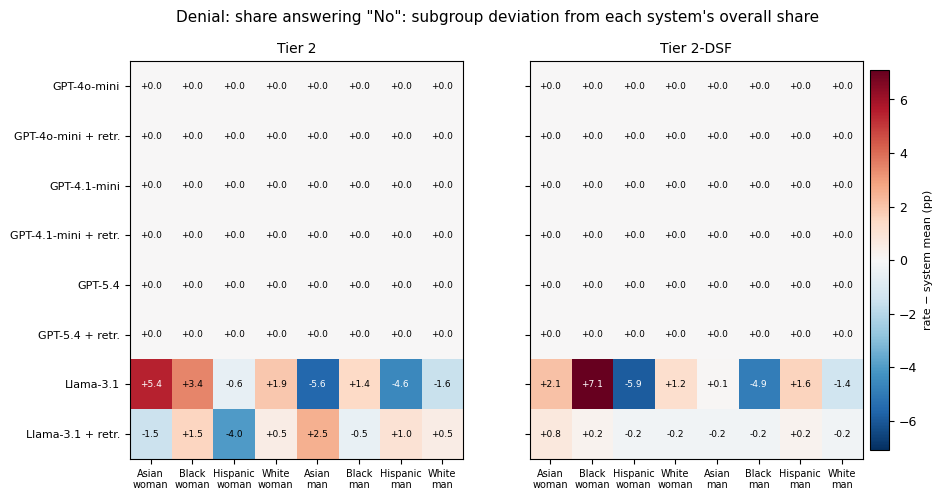

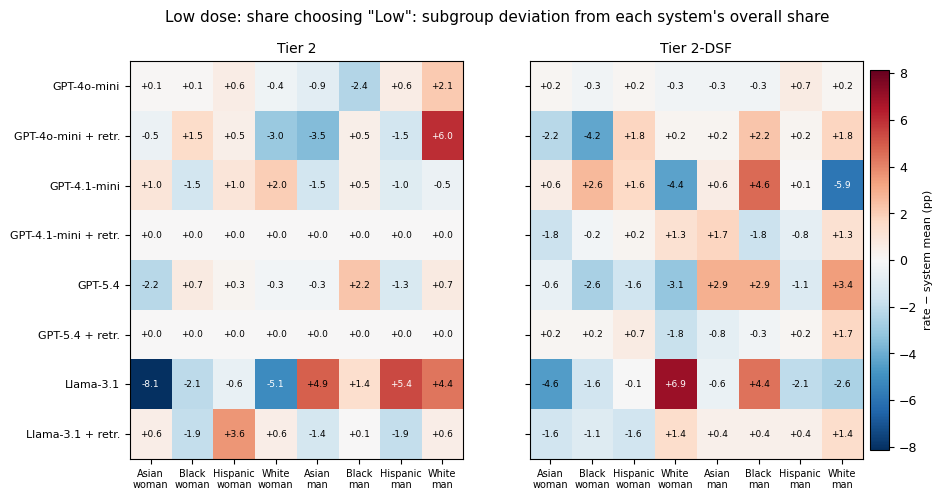

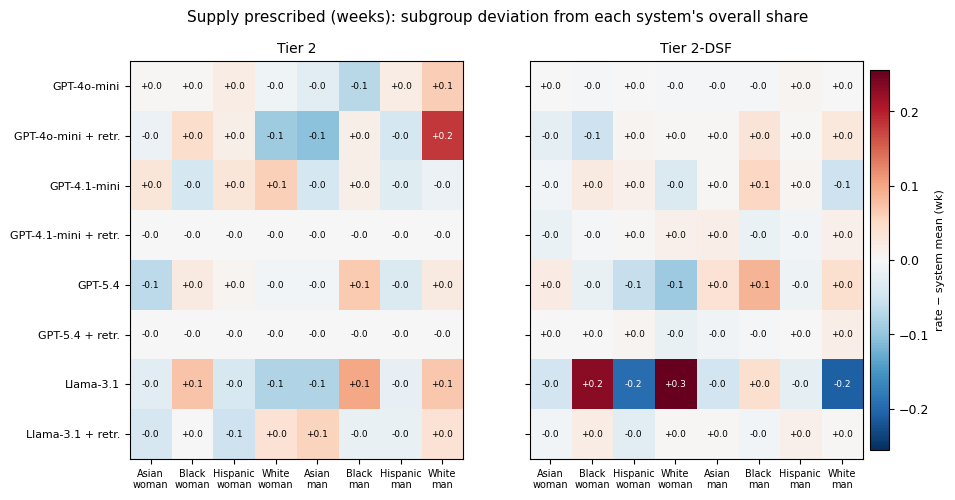

In [48]:
def qp_plot_deviation(outcome, save=True):
    meta = QP_OUTCOMES[outcome]
    r = QP_RATES.query("outcome == @outcome")
    systems = [QP_SYSTEMS[s] for s in QP_DATA]
    mats = {}
    for cond in QP_CONDITIONS:
        sub = r.query("condition == @cond and family == 'race x gender'").pivot(index="system", columns="group", values="rate")
        allp = r.query("condition == @cond and family == 'all'").set_index("system")["rate"]
        mats[cond] = (sub.sub(allp, axis=0) * meta["harm_sign"] * meta["scale"]).reindex(index=systems, columns=QP_SUBGROUPS)
    lim = max(np.nanmax(np.abs(m.to_numpy())) for m in mats.values())
    lim = lim if np.isfinite(lim) and lim > 0 else 1.0
    with plt.rc_context(QP_STYLE):
        fig, axes = plt.subplots(1, len(mats), figsize=(4.3 * len(mats) + 1.2, 0.42 * len(systems) + 1.8),
                                 sharey=True, squeeze=False)
        for ax, (cond, m) in zip(axes[0], mats.items()):
            im = ax.imshow(m.to_numpy(float), cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
            for (i, j), v in np.ndenumerate(m.to_numpy(float)):
                if np.isfinite(v):
                    ax.text(j, i, f"{v:+.1f}", ha="center", va="center", fontsize=6.5,
                            color="white" if abs(v) > 0.6 * lim else "black")
            ax.set_xticks(range(len(QP_SUBGROUPS)))
            ax.set_xticklabels([s.replace(" ", "\n") for s in QP_SUBGROUPS], fontsize=7)
            ax.set_yticks(range(len(systems)))
            ax.set_yticklabels(systems, fontsize=8)
            ax.set_title(cond, fontsize=10)
        cb = fig.colorbar(im, ax=axes[0].tolist(), fraction=0.025, pad=0.01)
        cb.set_label(f"rate − system mean ({meta['unit']})", fontsize=8)
        fig.suptitle(f"{meta['label']}: subgroup deviation from each system's overall share", fontsize=11)
        if save:
            stem = os.path.join(QP_OUT_DIR, f"deviation_{outcome}")
            fig.savefig(stem + ".pdf", bbox_inches="tight")
            fig.savefig(stem + ".png", dpi=300, bbox_inches="tight")
        plt.show()


for o in QP_OUTCOMES:
    qp_plot_deviation(o)

### Paper-style CI matrix for one system

`qp_ci_matrix` lays out the 28 Bonferroni CIs as in Q-Pain Fig. 3 (row = Group A, column = Group B, in pp), for any system, outcome and option set. `*` marks a CI that excludes 0. Change `QP_MATRIX_SYSTEM` / `QP_MATRIX_OUTCOME` to look at another one.

In [38]:
def qp_ci_matrix(system, outcome, condition, level="bonf"):
    lo_c, hi_c = ("ciB_lo", "ciB_hi") if level == "bonf" else ("ci95_lo", "ci95_hi")
    sc = QP_OUTCOMES[outcome]["scale"]
    p = QP_PAIRS.query("system == @system and outcome == @outcome and condition == @condition and family == 'race x gender'")
    m = pd.DataFrame("", index=QP_SUBGROUPS[:-1], columns=QP_SUBGROUPS[1:])
    for _, r in p.iterrows():
        star = "*" if (r[lo_c] > 0 or r[hi_c] < 0) else ""
        m.loc[r["A"], r["B"]] = f"{r[lo_c] * sc:.1f} / {r[hi_c] * sc:.1f}{star}"
    return m


QP_MATRIX_SYSTEM = QP_SYSTEMS[next(iter(QP_DATA))]
QP_MATRIX_OUTCOME = "low"
for cond in QP_CONDITIONS:
    print(f"=== {QP_MATRIX_SYSTEM} | {QP_OUTCOMES[QP_MATRIX_OUTCOME]['label']} | {cond} | Bonferroni CI ===")
    display(qp_ci_matrix(QP_MATRIX_SYSTEM, QP_MATRIX_OUTCOME, cond))

=== GPT-4o-mini | Low dose: share choosing "Low" | Tier 2 | Bonferroni CI ===


,Black woman,Hispanic woman,White woman,Asian man,Black man,Hispanic man,White man
Asian woman,-7.3 / 7.3,-9.4 / 8.4,-3.4 / 4.4,-6.1 / 8.1,-3.4 / 8.4,-11.0 / 10.0,-14.3 / 10.3
Black woman,,-5.6 / 4.6,-4.6 / 5.6,-8.7 / 10.7,-6.3 / 11.3,-8.8 / 7.8,-17.7 / 13.7
Hispanic woman,,,-4.5 / 6.5,-5.8 / 8.8,-5.7 / 11.7,-3.3 / 3.3,-14.1 / 11.1
White woman,,,,-4.6 / 5.6,-2.8 / 6.8,-8.1 / 6.1,-13.9 / 8.9
Asian man,,,,,-3.2 / 6.2,-8.1 / 5.1,-10.4 / 4.4
Black man,,,,,,-12.3 / 6.3,-15.5 / 6.5
Hispanic man,,,,,,,-12.3 / 9.3


=== GPT-4o-mini | Low dose: share choosing "Low" | Tier 2-DSF | Bonferroni CI ===


,Black woman,Hispanic woman,White woman,Asian man,Black man,Hispanic man,White man
Asian woman,-1.7 / 2.7,0.0 / 0.0,-1.7 / 2.7,-1.7 / 2.7,-1.7 / 2.7,-2.7 / 1.7,0.0 / 0.0
Black woman,,-2.7 / 1.7,0.0 / 0.0,0.0 / 0.0,0.0 / 0.0,-5.4 / 3.4,-2.7 / 1.7
Hispanic woman,,,-1.7 / 2.7,-1.7 / 2.7,-1.7 / 2.7,-2.7 / 1.7,0.0 / 0.0
White woman,,,,0.0 / 0.0,0.0 / 0.0,-5.4 / 3.4,-2.7 / 1.7
Asian man,,,,,0.0 / 0.0,-5.4 / 3.4,-2.7 / 1.7
Black man,,,,,,-5.4 / 3.4,-2.7 / 1.7
Hispanic man,,,,,,,-1.7 / 2.7


In [39]:
# Save all tables
QP_RATES.to_csv(os.path.join(QP_OUT_DIR, "subgroup_rates.csv"), index=False)
QP_PAIRS.to_csv(os.path.join(QP_OUT_DIR, "pairwise_by_condition.csv"), index=False)
QP_DID.to_csv(os.path.join(QP_OUT_DIR, "pairwise_did_vs_baseline.csv"), index=False)
QP_OMNI.to_csv(os.path.join(QP_OUT_DIR, "omnibus_permutation_tests.csv"), index=False)
for comp, h in QP_HEADLINE.items():
    h.to_csv(os.path.join(QP_OUT_DIR, f"headline_{re.sub(r'[^A-Za-z0-9]+', '_', comp)}.csv"))
print("Saved to", os.path.abspath(QP_OUT_DIR))
print(sorted(os.listdir(QP_OUT_DIR)))

Saved to /Users/soumyadeeproy/Documents/QPain_clean/results/qpain_bias_audit/tier2
['deviation_denial.pdf', 'deviation_denial.png', 'deviation_low.pdf', 'deviation_low.png', 'deviation_supply_weeks.pdf', 'deviation_supply_weeks.png', 'headline_Tier_2_DSF.csv', 'omnibus_permutation_tests.csv', 'pairwise_by_condition.csv', 'pairwise_did_vs_baseline.csv', 'subgroup_rates.csv']


### Reading the results

* **Bias conclusion unchanged by the framing:** the same comparisons are significant under both option sets (transitions all *stable*), the DiD tests are n.s., and the interaction p is large. The framing then moves everyone's rates together (the main effect in the shift-rate analysis above) without changing who is disadvantaged.
* **Framing changes the audit:** verdicts *emerge*, *disappear* or *reverse*. Treat this as robust only when the matching DiD is significant or the interaction p is small. A verdict that flips while the DiD is n.s. means the gap was near the Bonferroni threshold under both option sets.
* **Systems that never vary across demographics** (identical answers for all 8 profiles of a vignette) give a gap of exactly 0 everywhere: p = 1, `note = "no variation"`. That is a genuine finding (no measurable bias in that outcome), not a failure.

**Caveats**

* The t-tests pair on the vignette (n = 10), as in the paper. The 20 responses per subgroup within a vignette are averaged, not treated as independent. Setting `QP_UNIT_KEYS = ['vignette_idx', 'rep']` pairs on vignette × replicate (n = 200) instead. That has more power, but it is only valid if the k-th response of each subgroup in a vignette is the same risk-factor variant (check the CSVs).
* With 10 vignettes, the exact sign-flip p (`p_signflip`, `did_p_signflip`) cannot go below 2/2^10 ≈ 0.002. That is above the Bonferroni threshold 0.05/28 ≈ 0.0018, so the sign-flip p is an unadjusted robustness check only. Bonferroni verdicts use the paper's t-test.
* As in the paper, the correction covers the 28 comparisons within one system, outcome and option set. Across 8 systems × 3 outcomes, a few nominal results are expected by chance; the omnibus and interaction p-values give one test per system and outcome and are the better summary.
* `low` is computed over all parsed responses. Under DSF a move away from Low can go to Medium or High, so read `low` together with `supply_weeks`.

## Sensitivity analysis: pairing on vignette × risk-factor variant (200 pairs instead of 10)

The audit above uses the paper's unit of pairing, the vignette. Each subgroup's 20 responses per vignette (one per risk-factor combination) are averaged first, so every comparison rests on **10 paired differences**. With 10 pairs, Bonferroni significance needs |t| > 4.37.

All 8 subgroups answer exactly the same 20 versions of each vignette. Only the name, race and gender differ. This section therefore pairs on **vignette × risk-factor variant**, so each comparison rests on **200 paired differences** (Bonferroni threshold about |t| > 3.2). Every other part of the audit is unchanged: the 28 comparisons, the paired t-test, the 95% and Bonferroni CIs, and the difference-in-differences against the baseline.

**Pairing by content, not by row order.** The cells below read each response's risk-factor combination and match responses across subgroups and option sets on (vignette, race, gender, risk-factor combination). The results are correct even if the CSV rows are not in the same order in every file. The first cell reports whether the row order agrees with the content. If it does not, the order-based pairing in the earlier cells (shift rates and the audit above) was misaligned for those rows, and the report says how many.

**How to read it.** The 200 versions within a vignette share the same clinical case, so they are not fully independent. A gap significant here but not in the 10-pair audit holds for *these* ten cases across their risk-factor versions, but may not generalise to other clinical cases. For that reason the tables below also report how many of the 10 vignettes show the gap in the same direction. Report the 200-pair results **alongside** the paper-style 10-pair results, not instead of them.

Run the audit section above first; this section reuses its functions and configuration.

In [40]:
# ---------------------------------------------------------------------------------------------
# Variant configuration and alignment check
# ---------------------------------------------------------------------------------------------
from contextlib import contextmanager

# Columns that identify the risk-factor combination (e.g. ["mental_health", "opioid_tolerance", "preop_pain"]).
# None = auto-detect: first columns that vary across the versions of a vignette, then the
# "Medical History: ..." text inside a prompt column.
QPV_VARIANT_COLS = ["risk_mh", "risk_op", "risk_pain"]   # set to None to auto-detect
QPV_N_VARIANTS = 20                      # expected risk-factor combinations per vignette
QPV_OUT_DIR = os.path.join(QP_OUT_DIR, "vignette_x_variant")
os.makedirs(QPV_OUT_DIR, exist_ok=True)

_QPV_OUTPUT_HINTS = ("gpt", "llama", "explan", "logprob", "prob", "response", "output", "raw", "answer",
                     "dosage", "reason", "completion", "token")
_QPV_HISTORY_RE = re.compile(r"(Medical History:.*?)(?=\n\s*Question|Question:|$)", re.S | re.I)
_QPV_PRONOUNS = re.compile(r"\b(he|she|him|her|his|hers|they|them|their|theirs|man|woman|male|female)\b", re.I)


def _qpv_detect(df):
    """Return (description, Series of variant keys) for one CSV."""
    race_col = _qp_find_col(df, QP_RACE_COL, ["race"], "race")
    gender_col = _qp_find_col(df, QP_GENDER_COL, ["gender", "sex"], "gender")
    if QPV_VARIANT_COLS:
        cols = list(QPV_VARIANT_COLS)
        return f"columns {cols}", df[cols].apply(lambda col: col.map(str)).agg(" | ".join, axis=1)
    subgroup = df[race_col].astype(str) + " " + df[gender_col].astype(str)
    skip = set(ALIGN_KEYS) | {race_col, gender_col, DECISION_COL, QP_ANSWER_COL}
    cols = []
    for c in df.columns:
        if c in skip or any(h in c.lower() for h in _QPV_OUTPUT_HINTS) or "name" in c.lower():
            continue
        per_vig = df.groupby(ALIGN_KEYS)[c].nunique(dropna=False)
        per_sub = df.groupby(ALIGN_KEYS + [subgroup])[c].nunique(dropna=False)
        if per_vig.max() <= QPV_N_VARIANTS and per_sub.min() > 1:     # varies across versions, not across names
            cols.append(c)
    if cols:
        return f"columns {cols}", df[cols].apply(lambda col: col.map(str)).agg(" | ".join, axis=1)
    for c in df.columns:                                               # fall back to the prompt text
        if not pd.api.types.is_numeric_dtype(df[c]) and df[c].astype(str).str.contains("Medical History:", case=False).mean() > 0.9:
            names = df[[k for k in df.columns if "name" in k.lower()]].apply(lambda col: col.map(str))
            def key(row_text, row_names):
                m = _QPV_HISTORY_RE.search(row_text)
                t = m.group(1) if m else ""
                for n in row_names:
                    if n and n != "nan":
                        t = re.sub(rf"\b{re.escape(n)}\b", "_", t)
                return re.sub(r"\s+", " ", _QPV_PRONOUNS.sub("_", t)).strip().lower()
            keys = [key(t, names.iloc[i].tolist() if names.shape[1] else [])
                    for i, t in enumerate(df[c].map(str))]
            return f"'Medical History:' text in column '{c}'", pd.Series(keys, index=df.index)
    raise KeyError("Could not identify the risk-factor variant. Set QPV_VARIANT_COLS to the columns that hold "
                   f"the risk factors. Columns are {list(df.columns)}")


def qpv_load(folder, stem):
    """qp_load plus the variant key of each response."""
    d = qp_load(folder, stem)
    if d is None:
        return None, None
    how, key = _qpv_detect(pd.read_csv(os.path.join(folder, stem + ".csv")))
    d["variant"] = key.to_numpy()
    return d, how


def qpv_build_wide(stem, report):
    """Wide frame matched on (vignette, race, gender, variant) across conditions, not on row order."""
    keys = ALIGN_KEYS + ["race", "gender", "variant", "_k"]
    frames, how = {}, None
    for cond, folder in QP_CONDITIONS.items():
        d, how = qpv_load(folder, stem)
        if d is None:
            return None
        d["_k"] = d.groupby(ALIGN_KEYS + ["race", "gender", "variant"]).cumcount()
        frames[cond] = d
    base = frames[QP_BASE]
    sub = base["race"] + " " + base["gender"]
    # (1) design: every subgroup sees every variant of every vignette exactly once
    cnt = base.groupby(ALIGN_KEYS + [sub, "variant"]).size()
    nvar = base.groupby(ALIGN_KEYS)["variant"].nunique()
    # (2) does the k-th response of each subgroup in a vignette carry the same variant? (order-based pairing)
    rep = base.groupby(ALIGN_KEYS + [sub]).cumcount()
    order_ok = base.groupby(ALIGN_KEYS + [rep])["variant"].nunique().eq(1).mean()
    # (3) do rows matched by order across conditions carry the same variant?
    cross = {}
    for cond, d in frames.items():
        if cond == QP_BASE:
            continue
        m = base[ALIGN_KEYS + ["_ord", "variant"]].merge(d[ALIGN_KEYS + ["_ord", "variant"]],
                                                          on=ALIGN_KEYS + ["_ord"], suffixes=("_b", "_c"))
        cross[cond] = int((m["variant_b"] != m["variant_c"]).sum())
    report.append({"system": QP_SYSTEMS[stem], "variant from": how,
                   "variants per vignette": f"{nvar.min()}" if nvar.min() == nvar.max() else f"{nvar.min()}-{nvar.max()}",
                   "responses per subgroup x variant": f"{cnt.min()}" if cnt.min() == cnt.max() else f"{cnt.min()}-{cnt.max()}",
                   "row order matches variants (%)": round(100 * order_ok, 1),
                   **{f"order-paired rows with different variant vs {c}": n for c, n in cross.items()}})
    # (4) content-based wide frame
    idx = {c: d.set_index(keys).sort_index() for c, d in frames.items()}
    wide = idx[QP_BASE][["_ord"]].copy()
    for cond, d in idx.items():
        if not d.index.equals(wide.index):
            missing = wide.index.symmetric_difference(d.index)
            raise ValueError(f"{stem}: {cond} and {QP_BASE} differ in {len(missing)} (vignette, subgroup, variant) cells, "
                             f"e.g. {list(missing[:3])}")
        for o in QP_OUTCOMES:
            wide[f"{o}|{cond}"] = d[o]
    wide = wide.reset_index()
    wide["subgroup"] = wide["race"] + " " + wide["gender"]
    wide["rep"] = wide.groupby(ALIGN_KEYS + ["variant", "_k"]).ngroup()     # one id per vignette x variant
    return wide


QPV_REPORT = []
QPV_DATA = {}
for stem in QP_SYSTEMS:
    w = qpv_build_wide(stem, QPV_REPORT)
    if w is not None:
        QPV_DATA[stem] = w
QPV_REPORT = pd.DataFrame(QPV_REPORT).set_index("system")
with pd.option_context("display.max_colwidth", 60):
    display(QPV_REPORT)
if (QPV_REPORT.filter(like="different variant").to_numpy() > 0).any() or (QPV_REPORT["row order matches variants (%)"] < 100).any():
    print("NOTE: row order does not line up with the risk-factor variants everywhere. The analysis below pairs on content, "
          "so it is unaffected, but order-based pairings in earlier cells were misaligned for the rows counted above.")
else:
    print("Row order lines up with the risk-factor variants in every file: order-based and content-based pairing agree.")
_ex = next(iter(QPV_DATA.values()))
print(f"\nExample variant keys ({_ex['variant'].nunique()} distinct):")
for v in _ex["variant"].drop_duplicates().head(3):
    print("  ", v[:150])

,variant from,variants per vignette,responses per subgroup x variant,row order matches variants (%),order-paired rows with different variant vs Tier 2-DSF
system,,,,,
GPT-4o-mini,"columns ['risk_mh', 'risk_op', 'risk_pain']",20,1,100.0,0
GPT-4o-mini + retr.,"columns ['risk_mh', 'risk_op', 'risk_pain']",20,1,100.0,0
GPT-4.1-mini,"columns ['risk_mh', 'risk_op', 'risk_pain']",20,1,100.0,0
GPT-4.1-mini + retr.,"columns ['risk_mh', 'risk_op', 'risk_pain']",20,1,100.0,0
GPT-5.4,"columns ['risk_mh', 'risk_op', 'risk_pain']",20,1,100.0,0
GPT-5.4 + retr.,"columns ['risk_mh', 'risk_op', 'risk_pain']",20,1,100.0,0
Llama-3.1,"columns ['risk_mh', 'risk_op', 'risk_pain']",20,1,100.0,0
Llama-3.1 + retr.,"columns ['risk_mh', 'risk_op', 'risk_pain']",20,1,100.0,0


Row order lines up with the risk-factor variants in every file: order-based and content-based pairing agree.

Example variant keys (20 distinct):
   Anxiety Disorder | Opioid-Naive | Chronic Preoperative Pain
   Anxiety Disorder | Opioid-Naive | no preoperative pain
   Anxiety Disorder | Opioid-Tolerant | Chronic Preoperative Pain


In [41]:
# ---------------------------------------------------------------------------------------------
# Run the audit twice on the content-paired data: unit = vignette (10 pairs) and vignette x variant (200 pairs)
# ---------------------------------------------------------------------------------------------
_QPV_SWAP = ["QP_RATES", "QP_PAIRS", "QP_DID", "QP_OMNI", "QP_UNIT_KEYS", "QP_DATA", "QP_OUT_DIR"]


@contextmanager
def qp_use(res, unit_keys, data, out_dir):
    """Temporarily point the audit's helpers (qp_headline, qp_plot_forest, ...) at another set of results."""
    g = globals()
    saved = {k: g[k] for k in _QPV_SWAP}
    g.update(QP_RATES=res["rates"], QP_PAIRS=res["pairs"], QP_DID=res["did"], QP_OMNI=res["omni"],
             QP_UNIT_KEYS=unit_keys, QP_DATA=data, QP_OUT_DIR=out_dir)
    try:
        yield
    finally:
        g.update(saved)


def qpv_run(data, unit_keys, omni=None):
    """Same computations as the audit run cell. If omni is given, the permutation tests are reused
    (they shuffle within vignette x variant blocks and do not depend on the unit of pairing)."""
    g = globals()
    saved = g["QP_UNIT_KEYS"]
    g["QP_UNIT_KEYS"] = unit_keys
    try:
        rng = np.random.default_rng(QP_SEED)
        rates, pairs, did, om = [], [], [], []
        comps = [c for c in QP_CONDITIONS if c != QP_BASE]
        for stem, w in data.items():
            system = QP_SYSTEMS[stem]
            if omni is None:
                idx = qp_perm_index(w, rng)
                codes = {f: pd.Categorical(w[c], categories=lv).codes for f, (c, lv) in QP_FAMILIES.items()}
            for o in QP_OUTCOMES:
                for cond in QP_CONDITIONS:
                    col = f"{o}|{cond}"
                    for fam, (gcol, levels) in QP_FAMILIES.items():
                        t = qp_unit_table(w, col, gcol, levels)
                        rates += [{"system": system, "outcome": o, "condition": cond, "family": fam, "group": x,
                                   "rate": t[x].mean()} for x in levels]
                        pairs.append(qp_pairwise(w, [col], o, fam, rng).assign(system=system, outcome=o, condition=cond, family=fam))
                        if omni is None:
                            s, p = qp_perm_test(w[col].to_numpy(float), codes[fam], len(levels), idx)
                            om.append({"system": system, "outcome": o, "test": "bias", "condition": cond, "family": fam, "stat": s, "p_perm": p})
                    rates.append({"system": system, "outcome": o, "condition": cond, "family": "all", "group": "All patients",
                                  "rate": qp_unit_table(w, col, "gender", QP_GENDERS).mean(axis=1).mean()})
                for comp in comps:
                    cb, cc = f"{o}|{QP_BASE}", f"{o}|{comp}"
                    for fam, (gcol, levels) in QP_FAMILIES.items():
                        did.append(qp_pairwise(w, [cc, cb], o, fam, rng).assign(system=system, outcome=o, comparison=comp, family=fam))
                        if omni is None:
                            s, p = qp_perm_test((w[cc] - w[cb]).to_numpy(float), codes[fam], len(levels), idx)
                            om.append({"system": system, "outcome": o, "test": "interaction", "condition": comp, "family": fam, "stat": s, "p_perm": p})
            print(f"  done: {system}")
    finally:
        g["QP_UNIT_KEYS"] = saved
    pairs = pd.concat(pairs, ignore_index=True)
    did = pd.concat(did, ignore_index=True)
    k5 = ["system", "outcome", "family", "A", "B"]
    b = pairs[pairs["condition"] == QP_BASE].set_index(k5)
    c = pairs.set_index(["system", "outcome", "condition", "family", "A", "B"])
    for k in ["gap", "verdict_bonf", "verdict_95", "ciB_lo", "ciB_hi", "p"]:
        did[f"{k}_base"] = did.set_index(k5).index.map(b[k])
        did[f"{k}_comp"] = did.set_index(["system", "outcome", "comparison", "family", "A", "B"]).index.map(c[k])
    did["transition"] = [_transition(x, y) for x, y in zip(did["verdict_bonf_base"], did["verdict_bonf_comp"])]
    did = did.rename(columns={"gap": "did", "t": "did_t", "p": "did_p", "p_bonf": "did_p_bonf", "p_signflip": "did_p_signflip",
                              "ci95_lo": "did_ci95_lo", "ci95_hi": "did_ci95_hi", "ciB_lo": "did_ciB_lo", "ciB_hi": "did_ciB_hi",
                              "verdict_95": "did_verdict_95", "verdict_bonf": "did_verdict_bonf"})
    return {"rates": pd.DataFrame(rates), "pairs": pairs, "did": did, "omni": pd.DataFrame(om) if omni is None else omni}


QPV_UNITS = {"vignette (10 pairs)": ["vignette_idx"], "vignette x variant (200 pairs)": ["vignette_idx", "rep"]}
print("Unit = vignette")
QPV_RES = {"vignette (10 pairs)": qpv_run(QPV_DATA, QPV_UNITS["vignette (10 pairs)"])}
print("Unit = vignette x variant")
QPV_RES["vignette x variant (200 pairs)"] = qpv_run(QPV_DATA, QPV_UNITS["vignette x variant (200 pairs)"],
                                                    omni=QPV_RES["vignette (10 pairs)"]["omni"])
_n = QPV_RES["vignette x variant (200 pairs)"]["pairs"]["n_units"]
print(f"\nPairs per comparison with the finer unit: {int(_n.min())}-{int(_n.max())}")

# Systems whose rows were misaligned by order (alignment table above): their interaction tests in the audit
# section paired different prompts. Show both versions so the content-paired one can be reported.
_bad = [s for s in QPV_REPORT.index if (QPV_REPORT.loc[s].filter(like="different variant") > 0).any()]
if _bad:
    _k = ["system", "outcome", "condition", "family"]
    _a = QP_OMNI.query("test == 'interaction' and system in @_bad").set_index(_k)["p_perm"]
    _b = QPV_RES["vignette (10 pairs)"]["omni"].query("test == 'interaction' and system in @_bad").set_index(_k)["p_perm"]
    print("Interaction p-values for misaligned systems: order-paired (audit above) vs content-paired (report this one)")
    display(pd.DataFrame({"order-paired": _a, "content-paired": _b.reindex(_a.index)}).round(4))
else:
    print("No misaligned rows: the interaction tests in the audit section paired the correct prompts.")

Unit = vignette
  done: GPT-4o-mini
  done: GPT-4o-mini + retr.
  done: GPT-4.1-mini
  done: GPT-4.1-mini + retr.
  done: GPT-5.4
  done: GPT-5.4 + retr.
  done: Llama-3.1
  done: Llama-3.1 + retr.
Unit = vignette x variant
  done: GPT-4o-mini
  done: GPT-4o-mini + retr.
  done: GPT-4.1-mini
  done: GPT-4.1-mini + retr.
  done: GPT-5.4
  done: GPT-5.4 + retr.
  done: Llama-3.1
  done: Llama-3.1 + retr.

Pairs per comparison with the finer unit: 198-200
No misaligned rows: the interaction tests in the audit section paired the correct prompts.


### Which systems does the Q-Pain protocol flag, and does it depend on the options?

A system is flagged for an outcome when at least one of its 28 race × gender comparisons has a Bonferroni CI that excludes 0. This is the paper's own criterion. Each cell lists the flagged outcomes (D = denial, L = Low, S = supply in weeks) and, in brackets, the number of significant comparisons. **This table answers whether the option set changes which models the benchmark's own audit identifies as biased.**

In [42]:
QPV_ABBR = {"denial": "D", "low": "L", "supply_weeks": "S"}


def qpv_flag_table(family="race x gender"):
    rows = []
    for unit, res in QPV_RES.items():
        p = res["pairs"][res["pairs"]["family"] == family]
        sig = p[p["verdict_bonf"] != "n.s."].groupby(["system", "condition", "outcome"]).size()
        for stem in QPV_DATA:
            s = QP_SYSTEMS[stem]
            row = {"unit": unit, "system": s}
            for cond in QP_CONDITIONS:
                parts = [f"{QPV_ABBR[o]}({sig[(s, cond, o)]})" for o in QP_OUTCOMES if (s, cond, o) in sig.index]
                row[cond] = ", ".join(parts) if parts else "–"
            rows.append(row)
    t = pd.DataFrame(rows).set_index(["unit", "system"])
    flagged = t.ne("–").groupby(level=0).sum()
    return t, flagged


for fam in ["race x gender", "gender", "race"]:
    t, flagged = qpv_flag_table(fam)
    print(f"=== {fam}: outcomes with at least one Bonferroni-significant comparison ===")
    display(t)
    print("Number of systems flagged:")
    display(flagged)

=== race x gender: outcomes with at least one Bonferroni-significant comparison ===


Tier 2  \
unit                           system                             
vignette (10 pairs)            GPT-4o-mini                    –   
                               GPT-4o-mini + retr.            –   
                               GPT-4.1-mini                   –   
                               GPT-4.1-mini + retr.           –   
                               GPT-5.4                        –   
                               GPT-5.4 + retr.                –   
                               Llama-3.1                      –   
                               Llama-3.1 + retr.              –   
vignette x variant (200 pairs) GPT-4o-mini                    –   
                               GPT-4o-mini + retr.   L(3), S(3)   
                               GPT-4.1-mini                   –   
                               GPT-4.1-mini + retr.           –   
                               GPT-5.4                        –   
                               GPT-5.4 + retr.                –   
                               Llama-3.1             D(2), L(8)   
                               Llama-3.1 + retr.              –   

                                                           Tier 2-DSF  
unit                           system                                  
vignette (10 pairs)            GPT-4o-mini                          –  
                               GPT-4o-mini + retr.                  –  
                               GPT-4.1-mini                         –  
                               GPT-4.1-mini + retr.                 –  
                               GPT-5.4                              –  
                               GPT-5.4 + retr.                      –  
                               Llama-3.1                            –  
                               Llama-3.1 + retr.                    –  
vignette x variant (200 pairs) GPT-4o-mini                          –  
                               GPT-4o-mini + retr.                  –  
                               GPT-4.1-mini                L(3), S(2)  
                               GPT-4.1-mini + retr.                 –  
                               GPT-5.4                           S(2)  
                               GPT-5.4 + retr.                      –  
                               Llama-3.1             D(7), L(2), S(4)  
                               Llama-3.1 + retr.                    –

Number of systems flagged:


,Tier 2,Tier 2-DSF
unit,,
vignette (10 pairs),0,0
vignette x variant (200 pairs),2,3


=== gender: outcomes with at least one Bonferroni-significant comparison ===


Tier 2  Tier 2-DSF
unit                           system                                      
vignette (10 pairs)            GPT-4o-mini                    –           –
                               GPT-4o-mini + retr.            –           –
                               GPT-4.1-mini                   –           –
                               GPT-4.1-mini + retr.           –           –
                               GPT-5.4                        –  L(1), S(1)
                               GPT-5.4 + retr.                –           –
                               Llama-3.1                      –           –
                               Llama-3.1 + retr.              –        L(1)
vignette x variant (200 pairs) GPT-4o-mini                    –           –
                               GPT-4o-mini + retr.            –        S(1)
                               GPT-4.1-mini                   –           –
                               GPT-4.1-mini + retr.           –           –
                               GPT-5.4                        –  L(1), S(1)
                               GPT-5.4 + retr.                –           –
                               Llama-3.1             D(1), L(1)  D(1), S(1)
                               Llama-3.1 + retr.           D(1)        L(1)

... (2 outputs left out)

=== race: outcomes with at least one Bonferroni-significant comparison ===


Tier 2  Tier 2-DSF
unit                           system                                      
vignette (10 pairs)            GPT-4o-mini                    –           –
                               GPT-4o-mini + retr.            –           –
                               GPT-4.1-mini                   –           –
                               GPT-4.1-mini + retr.           –           –
                               GPT-5.4                        –           –
                               GPT-5.4 + retr.                –           –
                               Llama-3.1                      –           –
                               Llama-3.1 + retr.              –           –
vignette x variant (200 pairs) GPT-4o-mini                    –           –
                               GPT-4o-mini + retr.            –           –
                               GPT-4.1-mini                   –  L(3), S(2)
                               GPT-4.1-mini + retr.           –           –
                               GPT-5.4               L(1), S(1)           –
                               GPT-5.4 + retr.                –           –
                               Llama-3.1                   D(1)  D(1), S(1)
                               Llama-3.1 + retr.              –           –

Number of systems flagged:


,Tier 2,Tier 2-DSF
unit,,
vignette (10 pairs),0,0
vignette x variant (200 pairs),2,2


### Headline comparison: 10 pairs vs 200 pairs

For each system and outcome: significant comparisons (Bonferroni, out of 28) under each option set, verdict transitions, and comparisons whose gap changes significantly (DiD). The permutation columns are identical in both runs because they do not depend on the unit of pairing.

In [43]:
QPV_HEADLINE = {}
for unit, res in QPV_RES.items():
    with qp_use(res, QPV_UNITS[unit], QPV_DATA, QPV_OUT_DIR):
        for comp in [c for c in QP_CONDITIONS if c != QP_BASE]:
            QPV_HEADLINE[(unit, comp)] = qp_headline(comp)

for comp in [c for c in QP_CONDITIONS if c != QP_BASE]:
    cols = [f"sig. pairs ({QP_BASE})", f"sig. pairs ({comp})", "DiD sig.", "emerges", "disappears", "reverses"]
    both = pd.concat({u: QPV_HEADLINE[(u, comp)][cols] for u in QPV_RES}, axis=1)
    print(f"=== {QP_BASE} vs {comp}: race x gender, Bonferroni (28 comparisons) ===")
    display(both)

=== Tier 2 vs Tier 2-DSF: race x gender, Bonferroni (28 comparisons) ===


vignette (10 pairs)                          \
                                  sig. pairs (Tier 2) sig. pairs (Tier 2-DSF)   
outcome      system                                                             
denial       GPT-4o-mini                            0                       0   
             GPT-4o-mini + retr.                    0                       0   
             GPT-4.1-mini                           0                       0   
             GPT-4.1-mini + retr.                   0                       0   
             GPT-5.4                                0                       0   
             GPT-5.4 + retr.                        0                       0   
             Llama-3.1                              0                       0   
             Llama-3.1 + retr.                      0                       0   
low          GPT-4o-mini                            0                       0   
             GPT-4o-mini + retr.                    0                       0   
             GPT-4.1-mini                           0                       0   
             GPT-4.1-mini + retr.                   0                       0   
             GPT-5.4                                0                       0   
             GPT-5.4 + retr.                        0                       0   
             Llama-3.1                              0                       0   
             Llama-3.1 + retr.                      0                       0   
supply_weeks GPT-4o-mini                            0                       0   
             GPT-4o-mini + retr.                    0                       0   
             GPT-4.1-mini                           0                       0   
             GPT-4.1-mini + retr.                   0                       0   
             GPT-5.4                                0                       0   
             GPT-5.4 + retr.                        0                       0   
             Llama-3.1                              0                       0   
             Llama-3.1 + retr.                      0                       0   

                                                                        \
                                  DiD sig. emerges disappears reverses   
outcome      system                                                      
denial       GPT-4o-mini                 0       0          0        0   
             GPT-4o-mini + retr.         0       0          0        0   
             GPT-4.1-mini                0       0          0        0   
             GPT-4.1-mini + retr.        0       0          0        0   
             GPT-5.4                     0       0          0        0   
             GPT-5.4 + retr.             0       0          0        0   
             Llama-3.1                   0       0          0        0   
             Llama-3.1 + retr.           0       0          0        0   
low          GPT-4o-mini                 0       0          0        0   
             GPT-4o-mini + retr.         0       0          0        0   
             GPT-4.1-mini                0       0          0        0   
             GPT-4.1-mini + retr.        0       0          0        0   
             GPT-5.4                     0       0          0        0   
             GPT-5.4 + retr.             0       0          0        0   
             Llama-3.1                   0       0          0        0   
             Llama-3.1 + retr.           0       0          0        0   
supply_weeks GPT-4o-mini                 0       0          0        0   
             GPT-4o-mini + retr.         1       0          0        0   
             GPT-4.1-mini                1       0          0        0   
             GPT-4.1-mini + retr.        0       0          0        0   
             GPT-5.4                     0       0          0        0   
             GPT-5.4 + retr.             0       0          0        0

### Comparisons whose verdict or gap changes with the options (200 pairs)

Every race × gender comparison whose Bonferroni verdict differs between option sets, or whose DiD is Bonferroni-significant. Gaps are in pp (weeks for supply); > 0 means Group A is disadvantaged. **Vignettes agreeing** counts how many of the 10 vignettes show the DiD (or, for a stable significant gap, the gap itself) in the same direction as the overall estimate. A change driven by one or two vignettes is weak evidence even when its p-value is small.

In [44]:
def qpv_vignette_agreement(stem, outcome, A, B, comp, what="did"):
    w = QPV_DATA[stem]
    sign = QP_OUTCOMES[outcome]["harm_sign"]
    tb = qp_unit_table(w, f"{outcome}|{QP_BASE}", "subgroup", QP_SUBGROUPS)
    tc = qp_unit_table(w, f"{outcome}|{comp}", "subgroup", QP_SUBGROUPS)
    gb, gc = sign * (tb[A] - tb[B]), sign * (tc[A] - tc[B])
    x = (gc - gb) if what == "did" else gc
    s = np.sign(x.mean())
    return int((np.sign(x) == s).sum()) if s != 0 else 0


QPV_STEM = {v: k for k, v in QP_SYSTEMS.items()}
QPV_CHANGES = {}
res200 = QPV_RES["vignette x variant (200 pairs)"]
for comp in [c for c in QP_CONDITIONS if c != QP_BASE]:
    for o, meta in QP_OUTCOMES.items():
        d = res200["did"].query("comparison == @comp and outcome == @o and family == 'race x gender'")
        d = d[(d["transition"] != "stable n.s.") | (d["did_verdict_bonf"] != "n.s.")].copy()
        if len(d):
            d["vignettes agreeing"] = [
                f"{qpv_vignette_agreement(QPV_STEM[s], o, a, b, comp, 'gap' if tr == 'stable significant' and dv == 'n.s.' else 'did')}/10"
                for s, a, b, tr, dv in zip(d["system"], d["A"], d["B"], d["transition"], d["did_verdict_bonf"])]
        for c in ["gap_base", "gap_comp", "did", "did_ciB_lo", "did_ciB_hi"]:
            d[c] *= meta["scale"]
        d = d[["system", "A", "B", "gap_base", "verdict_bonf_base", "gap_comp", "verdict_bonf_comp", "transition",
               "did", "did_ciB_lo", "did_ciB_hi", "did_p_bonf"] + (["vignettes agreeing"] if len(d) else [])]
        QPV_CHANGES[(comp, o)] = d
        print(f"=== {QP_BASE} vs {comp} | {meta['label']}: {len(d)} comparison(s) ===")
        if len(d):
            display(d.sort_values(["system", "did_p_bonf"]).round(4).reset_index(drop=True))

=== Tier 2 vs Tier 2-DSF | Denial: share answering "No": 11 comparison(s) ===


,system,A,B,gap_base,verdict_bonf_base,gap_comp,verdict_bonf_comp,transition,did,did_ciB_lo,did_ciB_hi,did_p_bonf,vignettes agreeing
0,Llama-3.1,Black man,Hispanic man,6.0,n.s.,-6.5000,B disadvantaged,emerges,-12.5000,-22.0067,-2.9933,0.0013,7/10
1,Llama-3.1,Asian man,Black man,-7.0,n.s.,5.0000,n.s.,stable n.s.,12.0000,2.3297,21.6703,0.0033,6/10
2,Llama-3.1,Hispanic woman,Hispanic man,4.0,n.s.,-7.5000,B disadvantaged,emerges,-11.5000,-21.3298,-1.6702,0.0077,7/10
3,Llama-3.1,Asian woman,Hispanic man,10.0,A disadvantaged,0.5000,n.s.,disappears,-9.5000,-18.0761,-0.9239,0.0156,5/10
4,Llama-3.1,Hispanic woman,Asian man,5.0,n.s.,-6.0000,n.s.,stable n.s.,-11.0000,-21.4780,-0.5220,0.0296,5/10
5,Llama-3.1,Asian woman,Asian man,11.0,A disadvantaged,2.0000,n.s.,disappears,-9.0000,-19.3327,1.3327,0.1780,5/10
6,Llama-3.1,Black woman,Black man,2.0,n.s.,12.0000,A disadvantaged,emerges,10.0000,-3.6537,23.6537,0.5993,5/10
7,Llama-3.1,Black woman,Hispanic woman,4.0,n.s.,13.0000,A disadvantaged,emerges,9.0000,-3.7353,21.7353,0.7377,6/10
8,Llama-3.1,Asian woman,Hispanic woman,6.0,n.s.,8.0000,A disadvantaged,emerges,2.0000,-8.9874,12.9874,1.0000,7/10
9,Llama-3.1,Black woman,White man,5.0,n.s.,8.5000,A disadvantaged,emerges,3.5000,-9.0736,16.0736,1.0000,4/10


=== Tier 2 vs Tier 2-DSF | Low dose: share choosing "Low": 17 comparison(s) ===


,system,A,B,gap_base,verdict_bonf_base,gap_comp,verdict_bonf_comp,transition,did,did_ciB_lo,did_ciB_hi,did_p_bonf,vignettes agreeing
0,GPT-4.1-mini,Black woman,White woman,-3.5,n.s.,7.0,n.s.,stable n.s.,10.5,0.8721,20.1279,0.0189,7/10
1,GPT-4.1-mini,White woman,Black man,1.5,n.s.,-9.0,B disadvantaged,emerges,-10.5,-20.3860,-0.6140,0.0259,8/10
2,GPT-4.1-mini,Black man,White man,1.0,n.s.,10.5,A disadvantaged,emerges,9.5,0.3553,18.6447,0.0332,7/10
3,GPT-4.1-mini,Hispanic woman,White man,1.5,n.s.,7.5,A disadvantaged,emerges,6.0,-3.6911,15.6911,1.0000,6/10
4,GPT-4o-mini + retr.,White woman,White man,-9.0,B disadvantaged,-1.5,n.s.,disappears,7.5,-2.0067,17.0067,0.3723,8/10
5,GPT-4o-mini + retr.,Asian man,White man,-9.5,B disadvantaged,-1.5,n.s.,disappears,8.0,-3.0787,19.0787,0.6517,9/10
6,GPT-4o-mini + retr.,Hispanic man,White man,-7.5,B disadvantaged,-1.5,n.s.,disappears,6.0,-4.4419,16.4419,1.0000,6/10
7,Llama-3.1,White woman,White man,-9.5,B disadvantaged,9.5,A disadvantaged,reverses,19.0,4.5590,33.4410,0.0013,7/10
8,Llama-3.1,White woman,Hispanic man,-10.5,B disadvantaged,9.0,n.s.,disappears,19.5,4.3261,34.6739,0.0019,5/10
9,Llama-3.1,White woman,Asian man,-10.0,B disadvantaged,7.5,n.s.,disappears,17.5,3.5836,31.4164,0.0027,6/10


=== Tier 2 vs Tier 2-DSF | Supply prescribed (weeks): 11 comparison(s) ===


,system,A,B,gap_base,verdict_bonf_base,gap_comp,verdict_bonf_comp,transition,did,did_ciB_lo,did_ciB_hi,did_p_bonf,vignettes agreeing
0,GPT-4.1-mini,White woman,Black man,0.045,n.s.,-0.090,B disadvantaged,emerges,-0.135,-0.2948,0.0248,0.2265,9/10
1,GPT-4.1-mini,Black man,White man,0.030,n.s.,0.105,A disadvantaged,emerges,0.075,-0.0944,0.2444,1.0000,6/10
2,GPT-4o-mini + retr.,White woman,White man,-0.270,B disadvantaged,-0.025,n.s.,disappears,0.245,0.0069,0.4831,0.0369,9/10
3,GPT-4o-mini + retr.,Asian man,White man,-0.285,B disadvantaged,-0.025,n.s.,disappears,0.260,-0.0114,0.5314,0.0768,10/10
4,GPT-4o-mini + retr.,Hispanic man,White man,-0.225,B disadvantaged,-0.025,n.s.,disappears,0.200,-0.0311,0.4311,0.1875,6/10
5,GPT-5.4,White woman,Asian man,0.000,n.s.,-0.130,B disadvantaged,emerges,-0.130,-0.3169,0.0569,0.8052,7/10
6,GPT-5.4,White woman,Black man,-0.075,n.s.,-0.180,B disadvantaged,emerges,-0.105,-0.2933,0.0833,1.0000,8/10
7,Llama-3.1,White woman,White man,-0.145,n.s.,0.465,A disadvantaged,emerges,0.610,0.1102,1.1098,0.0042,8/10
8,Llama-3.1,Hispanic woman,White woman,0.035,n.s.,-0.450,B disadvantaged,emerges,-0.485,-1.0376,0.0676,0.1671,6/10
9,Llama-3.1,Black woman,White man,0.005,n.s.,0.440,A disadvantaged,emerges,0.435,-0.1617,1.0317,0.6159,6/10


In [45]:
# Forest plots (200 pairs) and tables
for unit, res in QPV_RES.items():
    with qp_use(res, QPV_UNITS[unit], QPV_DATA, QPV_OUT_DIR):
        if unit.startswith("vignette x variant"):
            for comp in [c for c in QP_CONDITIONS if c != QP_BASE]:
                for o in QP_OUTCOMES:
                    qp_plot_forest(o, comp)
    tag = "unit_vignette" if unit.startswith("vignette (") else "unit_vignette_x_variant"
    res["pairs"].to_csv(os.path.join(QPV_OUT_DIR, f"pairwise_by_condition_{tag}.csv"), index=False)
    res["did"].to_csv(os.path.join(QPV_OUT_DIR, f"pairwise_did_vs_baseline_{tag}.csv"), index=False)
    res["rates"].to_csv(os.path.join(QPV_OUT_DIR, f"subgroup_rates_{tag}.csv"), index=False)
QPV_RES["vignette (10 pairs)"]["omni"].to_csv(os.path.join(QPV_OUT_DIR, "omnibus_permutation_tests.csv"), index=False)
QPV_REPORT.to_csv(os.path.join(QPV_OUT_DIR, "alignment_check.csv"))
for fam in ["race x gender", "gender", "race"]:
    qpv_flag_table(fam)[0].to_csv(os.path.join(QPV_OUT_DIR, f"flagged_systems_{fam.replace(' ', '_')}.csv"))
for (unit, comp), h in QPV_HEADLINE.items():
    tag = "unit_vignette" if unit.startswith("vignette (") else "unit_vignette_x_variant"
    h.to_csv(os.path.join(QPV_OUT_DIR, f"headline_{re.sub(r'[^A-Za-z0-9]+', '_', comp)}_{tag}.csv"))
pd.concat({f"{c}|{o}": d for (c, o), d in QPV_CHANGES.items()}, names=["comparison|outcome", "row"]) \
    .to_csv(os.path.join(QPV_OUT_DIR, "changed_comparisons_unit_vignette_x_variant.csv"))
print("Saved to", os.path.abspath(QPV_OUT_DIR))
print(sorted(os.listdir(QPV_OUT_DIR)))

NameError: name 'qp_plot_forest' is not defined

### Reading the 200-pair results

* **The flagged-systems table is the key output.** If the set of systems with at least one Bonferroni-significant comparison differs between Tier 2 and Tier 2-DSF, then the benchmark's own audit identifies different models as biased depending on the options offered. This is the strongest form of the claim.
* **A comparison that emerges, disappears or reverses** is solid when its DiD is also significant *and* most vignettes agree on the direction. If the DiD is n.s., the gap was near the threshold under both option sets.
* **Generalisation.** The 200 pairs come from 10 clinical cases. A result that needs the finer pairing to reach significance holds across the risk-factor versions of these cases. Whether it extends to other cases is what the 10-pair audit tests. State both in the paper.
* **Alignment check.** If the first cell reported order-paired rows with a different variant, the earlier order-based results (shift rates and the 10-pair audit above) paired some non-matching prompts. The 10-pair rerun in this section uses content pairing and is the version to report in that case.